<img src="images/highway2.jpg" width="90%">

# Predictive Analytics & Forecasting
> Executive Master in Business Analytics and AI
> - Project 2026
> - Rita P. Ribeiro - University of Porto | INESC TEC
> - October 2026


## Description
You are part of an analytics team supporting a national road-safety authority. The organization wants to understand how historical highway-accident data can be used to support better road-safety decisions.

# The modeling data

`model_table.csv` covers **1 April 2018 (`ERA_START`) to 31 December 2025**: one row per region per day, with the target (`accidents`) and all features. Training, validation and test are **date ranges of this one table**, split by time, never randomly.

### Training rows start in 2019 Q3

The history features need a full year of data before each quarter's cutoff. For the quarters 2018Q2 to 2019Q2 that year is not complete yet, so some history columns are empty:

| Quarter | Cutoff | `hist_avg_365d` needs data from… | Available? |
|---|---|---|---|
| 2019Q2 | 1 Mar 2019 | 1 Mar 2018 | no: the data starts 1 Apr 2018, so the value is empty |
| **2019Q3** | 1 Jun 2019 | 1 Jun 2018 | **yes: the first complete quarter** |

- **The 2018 Q2–2019 Q2 data is still used:** the history features of later quarters are calculated from it (for example, `hist_avg_365d` for 2019 Q3 is the average from June 2018 to May 2019). Those days are just not training *rows*.
- **Why not train from 2018Q2?** The GLM cannot handle empty values. Starting all three models at 2019 Q3 means they train on exactly the same rows, so the comparison is fair. We give up 2,280 of 13,625 rows (about 17%).

### Training, validation and test

| Part | Period | Rows (region × day) | Used for |
|---|---|---|---|
| **Training** | 2019 Q3 up to each quarter's cutoff | 5,865 before 2023, growing each quarter | fitting the models |
| **Validation** | 2023 Q1 – 2024Q4 (8 quarters) | 3,655 (1,170 weekend/holiday) | comparing models, tuning, ensemble weights |
| **Test** | 2025 Q1 – 2025 Q4 (4 quarters) | 1,825 (585 weekend/holiday) | the final score, used once |

- **Rolling origin:** each quarter is predicted by a model trained only on the days before its cutoff (1 month before the quarter starts). The month between the cutoff and the quarter start is never used, because in real use it has not happened yet.
- **COVID days** (16 March – 30 June 2020) are left out of training.
- **All days are used for training.** The main score is measured on weekends and holidays (the days the planners use), with the all-days score as an extra.

# Task 3 - Training & Evaluating the models

Forecast the number of accidents with victims per region per day, for every weekend day and holiday of the next quarter, 1 month before the quarter starts.

**Contents**
1. Setup
2. How we evaluate
3. Baseline
4. Model 1 - GLM Poisson regression
5. Model 2 - XGBoost
6. Model 3 - Random Forest
7. Comparison
8. Ensemble
9. Final test and interpretation
10. Conclusions and limitations

--------
## 1. Setup

In [83]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_poisson_deviance
from xgboost import XGBRegressor
import os
import seaborn as sns
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score
from sklearn.inspection import DecisionBoundaryDisplay

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data/processed"

# Shared calendar and region functions (src/features.py)
sys.path.append(str(ROOT / "src"))
from features import REGIONS, REGION_EN, build_calendar, get_brazil_holidays, assign_region, haversine_km

# model_table.csv is created in 02_Data_Understanding_Preparation.ipynb, section 6.4
model_table = pd.read_csv(PROCESSED / "model_table.csv", parse_dates=["date"])
model_table.head()

# ---- decisions agreed in Task 1 ----
LEAD_MONTHS = 1         # data cutoff (ref_date) = 1 month before the quarter starts
WINDOW_DAYS = 3         # holiday window = holiday date +/- 3 days
QUARTER_DAYS = 91       # "last quarter" = the 91 days up to the cutoff
ERA_START = pd.Timestamp("2018-04-01")   # start of the modelling period
# Target = accidents with victims = injury (1) or fatal (2) per region per day. Class 0 is excluded. 

REGIONS = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]

# plotting: restrained palette, light grid, no top/right spines
BLUE, ORANGE, GREY, DARK = "#2F6DB5", "#D9622B", "#8A8F98", "#222222"
REGION_COLORS = dict(zip(REGIONS, [BLUE, ORANGE, "#1B998B", "#7A5FB5", "#C79A1E"]))
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E3E5E8", "grid.linewidth": 0.7, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": DARK, "text.color": DARK, "xtick.color": DARK, "ytick.color": DARK,
    "legend.frameon": False, "figure.figsize": (8, 3.6),
})
pd.set_option("display.max_columns", 50, "display.width", 140, "display.float_format", "{:,.3f}".format)

--------
## 2. How we evaluate

- **Split by time, never randomly.**
- **Rolling backtest:** for each past quarter, train on data up to 1 month before the quarter starts, then predict that quarter's weekends and holidays.
- The **last quarters are kept as a final test** and are only used in section 9.
- **Metrics:** MAE, RMSE and Poisson deviance, with Poisson deviance as the main one (definitions and reasons in section 2.3).
- The backtest periods are defined **once** here and reused by every model, so the ensemble can combine predictions for exactly the same days.

Decision:
which days to train on. Our forecast only weekends and holidays, which are 908 of the 2,832 days. I'd suggest:

* Train on all days, with is_weekend and is_holiday as features. 
* That's three times more data, and weekdays still teach the model each region's level and trend.
* Evaluate only on weekends and holidays, because those are the days the planners use.

### Learning = Representation + Evaluation + Optimisation

Every model in this notebook is built in the same three steps, in this order (Domingos, 2012, *A Few Useful Things to Know About Machine Learning*):

| Step | Question | In this notebook |
|---|---|---|
| **1. Representation** | What form can the model take, and which inputs does it see? | the model family (rule, GLM, trees) and the features (section 2.4) |
| **2. Evaluation** | How do we decide that one model is better than another? | the loss minimised during training, and the metrics on the validation quarters (section 2.3) |
| **3. Optimisation** | How do we find the best model of that form? | fitting the parameters (coefficients, trees), and tuning the settings on the validation quarters |

**Why this order**
- The representation fixes which models are possible at all. A linear formula cannot learn what it has no term for; a tree cannot predict outside the range of its training data.
- The evaluation is fixed **before** optimising. Otherwise we could end up picking the metric that makes a model look good.
- The optimisation then searches only within the representation, and only for the evaluation chosen.

**Evaluation and optimisation happen at two levels**
- **Inner level (training):** the algorithm fits the parameters by minimising a loss on the training days. For all our models this loss is the Poisson deviance (the same as maximising the Poisson log-likelihood).
- **Outer level (model selection):** we choose the formulas, the settings and, finally, the model by the metrics on the validation quarters (rolling backtest). The final test quarters are not used at either level.

| Model | Representation | Evaluation (training loss) | Optimisation |
|---|---|---|---|
| Baseline (section 3) | one number per region and quarter: a history average | none: nothing is fitted | none: no parameters |
| GLM Poisson (section 4) | $\log \mu = \beta_0 + \beta_1 x_1 + \dots + \beta_k x_k$: a linear model on the log scale | Poisson log-likelihood (= Poisson deviance) | IRLS, an exact method; the formula is chosen on validation |
| XGBoost (section 5) | $\log \mu$ = a sum of many small trees | Poisson loss (`count:poisson`) | gradient boosting, one tree at a time; depth and number of trees tuned on validation |
| Random Forest (section 6) | $\mu$ = the average of many trees, each grown on a bootstrap sample; learns the ratio to the region's level | Poisson criterion at each split | greedy split search in each tree; leaf size, features per split and target chosen on validation |

All models are compared with the same validation metrics (section 2.3), on the same rows. $\mu$ is the expected number of accidents for one region on one day.

### 2.1. Define the backtest periods - Train end, cutoff, forecast quarter

In [84]:
model_table.info()

<class 'pandas.DataFrame'>
RangeIndex: 14160 entries, 0 to 14159
Data columns (total 32 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   region                 14160 non-null  str           
 1   date                   14160 non-null  datetime64[us]
 2   accidents              14160 non-null  int64         
 3   region_en              14160 non-null  str           
 4   is_covid               14160 non-null  int64         
 5   month                  14160 non-null  int64         
 6   rain_day_prob          14160 non-null  float64       
 7   heavy_rain_prob        14160 non-null  float64       
 8   avg_daily_precip       14160 non-null  float64       
 9   avg_temp_max           14160 non-null  float64       
 10  avg_humidity_min       14160 non-null  float64       
 11  fire_weather_prob      14160 non-null  float64       
 12  wildfire_season        14160 non-null  int64         
 13  year        

In [85]:
model_table_copy = model_table.copy()

In [86]:
# 2.1.1. Define the train start and the forecast quarters (validation + final test)
TARGET = "accidents"
TRAIN_START = pd.Timestamp("2019-07-01")   # 2019 Q3: first quarter with complete history features

quarters = pd.period_range("2023Q1", "2025Q4", freq="Q")
periods = pd.DataFrame({
    "quarter": quarters.astype(str),
    "q_start": quarters.start_time,
    "q_end": quarters.end_time.normalize(),
})

In [87]:
# 2.1.2. Define the cutoff: 1 month before the quarter starts, training uses only days before it
periods["cutoff"] = periods["q_start"] - pd.DateOffset(months=LEAD_MONTHS)

In [88]:
# 2.1.3. Define the forecast quarters and the final test quarters
# 2023-2024 = validation (backtest, model comparison, tuning), 2025 = final test (used once in section 9)
periods["role"] = np.where(periods["q_start"] < "2025-01-01", "validation", "test")

def split_period(p, features):
    """Train = TRAIN_START up to the cutoff (no COVID days); test = all days of the forecast quarter."""
    d = model_table
    train = d[(d["date"] >= TRAIN_START) & (d["date"] < p.cutoff) & ~d["is_covid"].astype(bool)]
    test = d[(d["date"] >= p.q_start) & (d["date"] <= p.q_end)]
    return train[features], train[TARGET], test[features], test[TARGET]

periods

,quarter,q_start,q_end,cutoff,role
0,2023Q1,2023-01-01,2023-03-31,2022-12-01,validation
1,2023Q2,2023-04-01,2023-06-30,2023-03-01,validation
2,2023Q3,2023-07-01,2023-09-30,2023-06-01,validation
3,2023Q4,2023-10-01,2023-12-31,2023-09-01,validation
4,2024Q1,2024-01-01,2024-03-31,2023-12-01,validation
5,2024Q2,2024-04-01,2024-06-30,2024-03-01,validation
6,2024Q3,2024-07-01,2024-09-30,2024-06-01,validation
7,2024Q4,2024-10-01,2024-12-31,2024-09-01,validation
8,2025Q1,2025-01-01,2025-03-31,2024-12-01,test
9,2025Q2,2025-04-01,2025-06-30,2025-03-01,test


* TARGET, TRAIN_START (1 July 2019, the start of 2019 Q3) and the 12 forecast quarters (2023 Q1 to 2025 Q4), each with its start and end date.
* cutoff for each quarter: 1 month before the quarter starts (for example, 1 Dec 2022 for 2023 Q1).
* 2023-2024 is the validation and 2025 is the test. split_period & features gives training data from TRAIN_START up to the cutoff (leaving COVID days left out) and test data covering every day of that quarters. 

* Decisions to make:
    * Leave the empty values. For example, using hist_avg_365d where hist_avg_91d is empty. and setting hist_trend to 0?
    * Fill the empty values. For example, using hist_avg_365d where hist_avg_91d is empty, and setting hist_trend to 0?
    * Drop 2020 Q3 and 2021 Q2 from the GLM training rows. But then all three models no longer train on the same rows, which section 1 says they should?

### 2.2. Fill the history features in the COVID gap

COVID days (16 March – 30 June 2020) are left out of the history averages, so two training quarters have empty history features:

| Feature | Empty in | Why | Filled with |
|---|---|---|---|
| `hist_avg_91d` | 2020 Q3 (460 rows) | the 91 days before the 1 June 2020 cutoff are almost all COVID days | `hist_avg_365d` |
| `hist_trend` | 2020 Q3 (460 rows) | it is `hist_avg_91d` / `hist_avg_365d` | 1 = "no trend" (follows from the fill above) |
| `hist_same_q_last_year` | 2021 Q2 (455 rows) | the same quarter last year is 2020 Q2, which was entirely COVID | `hist_avg_365d` |

- **No leakage:** `hist_avg_365d` is the 12-month average before the **same cutoff**, so a planner had that number on the forecast day. Nothing after the cutoff is used, and no average over the whole table is used.
- **Small:** about 4% of the training rows of the last quarter, for each feature.
- **Flag columns:** `hist_91d_filled` and `hist_same_q_filled` are 1 on the filled rows, so the models can treat those rows differently if they behave differently.
- **Same rule for training and test:** the fill is done on `model_table` itself, so every row goes through the same rule. No validation or test quarter has empty history today.
- **Why not drop the rows?** The GLM cannot handle empty values. Dropping 2020 Q3 and 2021 Q2 for the GLM only would make it train on different rows from XGBoost and Random Forest, and the comparison would no longer be fair.

In [89]:
# check of NaN values for the GLM Model 
# Empty values per column in the training rows of one period
p = periods.iloc[-1]   # last period = most training rows
X_train, y_train, X_test, y_test = split_period(p, model_table.columns.drop(TARGET))
na = X_train.isna().sum()
na[na > 0]


holiday_name             10270
days_to_holiday           9240
days_after_holiday        9240
hist_avg_91d               460
hist_same_q_last_year      455
hist_trend                 460
dtype: int64

In [90]:
# 2.2.1. Flag and fill the history features that are empty because of the COVID gap

# Flags first: they record which values were empty before the fill
if "hist_91d_filled" not in model_table.columns:
    model_table["hist_91d_filled"] = model_table["hist_avg_91d"].isna().astype(int)
    model_table["hist_same_q_filled"] = model_table["hist_same_q_last_year"].isna().astype(int)

# Fill with the 365-day average at the same cutoff (known on the forecast day, so no leakage)
model_table["hist_avg_91d"] = model_table["hist_avg_91d"].fillna(model_table["hist_avg_365d"])
model_table["hist_same_q_last_year"] = model_table["hist_same_q_last_year"].fillna(model_table["hist_avg_365d"])

# hist_trend = hist_avg_91d / hist_avg_365d, so the filled rows get 1 ("no trend")
model_table["hist_trend"] = model_table["hist_trend"].fillna(model_table["hist_avg_91d"] / model_table["hist_avg_365d"])

In [91]:
model_table

,region,date,accidents,region_en,is_covid,month,rain_day_prob,heavy_rain_prob,avg_daily_precip,avg_temp_max,avg_humidity_min,fire_weather_prob,wildfire_season,year,quarter,day,day_of_week,is_weekend,holiday_name,is_holiday,days_to_holiday,days_after_holiday,is_holiday_window,is_bridge_day,is_long_weekend,is_school_vacation,year_quarter,hist_avg_91d,hist_avg_365d,hist_dayoff_avg_365d,hist_same_q_last_year,hist_trend,hist_91d_filled,hist_same_q_filled
0,Norte,2018-04-01,0,North,0,4,0.798,0.082,8.459,29.280,69.496,0.003,0,2018,2,1,Sunday,1,NaN,0,NaN,2.000,1,0,1,0,2018Q2,NaN,NaN,NaN,NaN,NaN,1,1
1,Norte,2018-04-02,0,North,0,4,0.798,0.082,8.459,29.280,69.496,0.003,0,2018,2,2,Monday,0,NaN,0,NaN,3.000,1,0,0,0,2018Q2,NaN,NaN,NaN,NaN,NaN,1,1
2,Norte,2018-04-03,0,North,0,4,0.798,0.082,8.459,29.280,69.496,0.003,0,2018,2,3,Tuesday,0,NaN,0,NaN,NaN,0,0,0,0,2018Q2,NaN,NaN,NaN,NaN,NaN,1,1
3,Norte,2018-04-04,1,North,0,4,0.798,0.082,8.459,29.280,69.496,0.003,0,2018,2,4,Wednesday,0,NaN,0,NaN,NaN,0,0,0,0,2018Q2,NaN,NaN,NaN,NaN,NaN,1,1
4,Norte,2018-04-05,1,North,0,4,0.798,0.082,8.459,29.280,69.496,0.003,0,2018,2,5,Thursday,0,NaN,0,NaN,NaN,0,0,0,0,2018Q2,NaN,NaN,NaN,NaN,NaN,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14155,Sul,2025-12-27,5,South,0,12,0.513,0.069,5.359,26.986,59.865,0.015,0,2025,4,27,Saturday,1,NaN,0,NaN,2.000,1,0,1,1,2025Q4,3.264,3.419,3.403,3.674,0.955,0,0
14156,Sul,2025-12-28,1,South,0,12,0.513,0.069,5.359,26.986,59.865,0.015,0,2025,4,28,Sunday,1,NaN,0,3.000,3.000,1,0,1,1,2025Q4,3.264,3.419,3.403,3.674,0.955,0,0
14157,Sul,2025-12-29,4,South,0,12,0.513,0.069,5.359,26.986,59.865,0.015,0,2025,4,29,Monday,0,NaN,0,2.000,NaN,1,0,0,1,2025Q4,3.264,3.419,3.403,3.674,0.955,0,0
14158,Sul,2025-12-30,3,South,0,12,0.513,0.069,5.359,26.986,59.865,0.015,0,2025,4,30,Tuesday,0,NaN,0,1.000,NaN,1,0,0,1,2025Q4,3.264,3.419,3.403,3.674,0.955,0,0


In [92]:
# 2.2.2. Check: the filled rows per quarter, and no empty left in the training rows
HIST_COLS = ["hist_avg_91d", "hist_avg_365d", "hist_dayoff_avg_365d", "hist_same_q_last_year", "hist_trend"]
FLAG_COLS = ["hist_91d_filled", "hist_same_q_filled"]

X_train, _, _, _ = split_period(periods.iloc[-1], ["year_quarter"] + HIST_COLS + FLAG_COLS)   # last period = most training rows
print("Empty history values in training:", int(X_train[HIST_COLS].isna().sum().sum()))
print(f"Training rows: {len(X_train):,}")
X_train.groupby("year_quarter")[FLAG_COLS].sum().query("hist_91d_filled > 0 or hist_same_q_filled > 0")

Empty history values in training: 0
Training rows: 10,735


,hist_91d_filled,hist_same_q_filled
year_quarter,,
2020Q3,460,0
2021Q2,0,455


**Result:** no empty history values are left in the training rows. Only 2020 Q3 (`hist_91d_filled`) and 2021 Q2 (`hist_same_q_filled`) are filled, about 4% of the training rows each.

For the report: *History features that fall inside the COVID gap were replaced by the 365-day average available at the forecast cutoff (about 4% of training rows), so no information after the cutoff is used. A flag column marks the filled rows.*

Add `hist_91d_filled` and `hist_same_q_filled` to the feature list of each model.

### 2.3. Metrics and the backtest loop

Defined once and used by the baseline and every model, so all of them are scored on exactly the same rows:

- `score(y, pred)`: MAE, RMSE and Poisson deviance.
- `backtest(fit_predict, features)`: for each validation quarter, trains on the days before its cutoff and predicts every day of the quarter. Returns one row per region and day, with the actual value `y`, the prediction `pred` and `is_day_off` (weekend or holiday).
- `score_table(PREDS)`: scores every model in `PREDS`, on weekends and holidays by default (the days the planners use).
- `PREDS`: each section adds its validation predictions here, for the comparison (section 7) and the ensemble (section 8).

#### The metrics: definitions and why we use them

For $n$ rows (one per region and day), with $y_i$ the actual number of accidents and $\hat{y}_i$ the prediction:

| Metric | Formula | Unit | What it measures |
|---|---|---|---|
| **MAE** (mean absolute error) | $\frac{1}{n}\sum_i \lvert y_i - \hat{y}_i \rvert$ | accidents | the average miss, in accidents per region and day |
| **RMSE** (root mean squared error) | $\sqrt{\frac{1}{n}\sum_i (y_i - \hat{y}_i)^2}$ | accidents | like MAE, but big misses count more, because they are squared |
| **Poisson deviance** (mean) | $\frac{2}{n}\sum_i \left[ y_i \log\frac{y_i}{\hat{y}_i} - (y_i - \hat{y}_i) \right]$ | none | how well the predicted rate fits the counts, if the counts are Poisson ($y_i \log y_i = 0$ when $y_i = 0$) |

Lower is better for all three. The main score uses the weekend/holiday rows of the validation quarters; the all-days score is an extra.

**Why these three**
- **MAE** is the easiest to explain to the planners: "on average, the forecast is 1.2 accidents off per region and day". But MAE is minimised by the median, not the mean, so on skewed counts it rewards predicting slightly low. That is why `naive_all_days_365d` wins on MAE in section 3.
- **RMSE** has the same unit, but it penalises big misses more. A busy holiday with 8 accidents where 2 were predicted matters for planning. RMSE is minimised by the mean, which is what we forecast (the expected number of accidents). Its limit: for counts, even a perfect model has an RMSE of about $\sqrt{\text{mean}}$ (about 1.53 here).
- **Poisson deviance is the main metric:**
  - It is made for counts. A miss of 2 accidents counts more when 1 was predicted than when 10 were predicted, because the spread of a count grows with its mean.
  - It is the loss the models minimise during training (GLM, XGBoost `count:poisson`, Random Forest `criterion="poisson"`), so evaluation and optimisation measure the same thing.
  - Like RMSE, it is minimised by the true mean.
  - It needs predictions above 0, so `score()` clips them at 0.000001.
- **When the metrics disagree**, we decide on the Poisson deviance, and report MAE and RMSE because they are easier to read.

**Why not other metrics**
- **MAPE** (mean absolute percentage error) divides by $y_i$. 18% of the validation weekend/holiday rows have 0 accidents (53% in Norte), so it is undefined there.
- **R²**: most of the day-to-day variation is chance, so R² stays small even for a good model and is hard to compare across regions.
- **Accuracy and other classification metrics**: the target is a count, not a class.

In [93]:
# 2.3.1. Metrics and the backtest loop, shared by the baseline and every model
def score(y, pred):
    """MAE, RMSE and Poisson deviance (the deviance needs predictions above 0)."""
    return pd.Series({
        "MAE": mean_absolute_error(y, pred),
        "RMSE": mean_squared_error(y, pred) ** 0.5,
        "Poisson_dev": mean_poisson_deviance(y, np.clip(pred, 1e-6, None)),
        "n_rows": len(y),
    })

def backtest(fit_predict, features, role="validation"):
    """For every quarter of the given role: train up to its cutoff, predict all its days.
    fit_predict(X_train, y_train, X_test) returns the predictions. One row per region and day."""
    out = []
    for p in periods[periods["role"] == role].itertuples():
        X_tr, y_tr, X_te, y_te = split_period(p, features)
        rows = model_table.loc[X_te.index, ["region", "date", "is_weekend", "is_holiday"]]
        out.append(rows.assign(quarter=p.quarter, y=y_te, pred=np.asarray(fit_predict(X_tr, y_tr, X_te))))
    out = pd.concat(out)
    out["is_day_off"] = (out["is_weekend"] == 1) | (out["is_holiday"] == 1)   # the days the planners use
    return out

def score_table(preds, by=None, day_off_only=True):
    """Scores of each model in preds = {name: backtest output}, on weekends and holidays by default."""
    rows = []
    for name, df in preds.items():
        df = df[df["is_day_off"]] if day_off_only else df
        groups = df.groupby(by) if by else [("all", df)]
        for key, g in groups:
            rows.append(score(g["y"], g["pred"]).rename((name, key)))
    return pd.DataFrame(rows).astype({"n_rows": int}).rename_axis(["model", by or ""])

PREDS = {}   # validation predictions of every model, filled section by section

### 2.4. Features

The GLM gets its own formula in section 4. The tree models (XGBoost, Random Forest) use the `FEATURES` list below.

| Group | Columns | Note |
|---|---|---|
| Region | `region_Norte` … `region_Sul` | one column per region (1/0) |
| Calendar | `month`, `dow` (0 = Monday), `is_weekend`, `is_holiday`, `days_to_holiday`, `days_after_holiday`, holiday window, bridge day, long weekend, school vacation | known in advance |
| Weather | rain, heavy rain, precipitation, temperature, humidity, fire weather, wildfire season | monthly averages per region, the same every year, so known in advance |
| History | the five `hist_*` columns and the two `*_filled` flags | computed at the cutoff |

Left out: `date`, `year`, `day`, `quarter` (`month` covers it), `is_covid` (COVID days are not in training), and the text columns.

In [94]:
# 2.4.1. Feature preparation and the feature list for the tree models
DOW = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
model_table["dow"] = model_table["day_of_week"].map({d: i for i, d in enumerate(DOW)})   # 0 = Monday
for r in REGIONS:
    model_table[f"region_{r}"] = (model_table["region"] == r).astype(int)

REGION_COLS = [f"region_{r}" for r in REGIONS]
CALENDAR_COLS = ["month", "dow", "is_weekend", "is_holiday", "days_to_holiday", "days_after_holiday",
                 "is_holiday_window", "is_bridge_day", "is_long_weekend", "is_school_vacation"]
WEATHER_COLS = ["rain_day_prob", "heavy_rain_prob", "avg_daily_precip", "avg_temp_max", "avg_humidity_min",
                "fire_weather_prob", "wildfire_season"]
FEATURES = REGION_COLS + CALENDAR_COLS + WEATHER_COLS + HIST_COLS + FLAG_COLS
print(len(FEATURES), "features:", FEATURES)

29 features: ['region_Norte', 'region_Nordeste', 'region_Centro-Oeste', 'region_Sudeste', 'region_Sul', 'month', 'dow', 'is_weekend', 'is_holiday', 'days_to_holiday', 'days_after_holiday', 'is_holiday_window', 'is_bridge_day', 'is_long_weekend', 'is_school_vacation', 'rain_day_prob', 'heavy_rain_prob', 'avg_daily_precip', 'avg_temp_max', 'avg_humidity_min', 'fire_weather_prob', 'wildfire_season', 'hist_avg_91d', 'hist_avg_365d', 'hist_dayoff_avg_365d', 'hist_same_q_last_year', 'hist_trend', 'hist_91d_filled', 'hist_same_q_filled']


### 2.5. Charts, tables and feature importance shared by all models

Every model is shown in the same way, so the sections can be compared side by side. The charts and tables are defined once here and called in the model sections (4 and 5), the comparison (7), the ensemble (8) and the final test (9).

| Function | What it shows | Used in |
|---|---|---|
| `plot_weekly(name)` | the weekly average per weekend/holiday day, 5 regions: actual, the model's forecast and the normal level (baseline) | 4.5, 5.4 |
| `quarter_totals_table(name)` | quarter totals on weekends and holidays (5 regions): actual, forecast, baseline and their errors | 4.5, 5.4 |
| `plot_quarter_regions(name, quarter)` | one quarter per region: the year before the cutoff, the 1-month gap, then the forecast with an 80% range | 4.5, 5.4 |
| `plot_quarter_totals(name)` | quarter totals from 2019 Q3, then the forecast with an 80% range: 5 regions together, then per region | 4.6, 5.5 |
| `region_errors_table(name)` | the average miss of the quarter totals per region, and how many quarters fall inside the 80% range | 4.6, 5.5 |
| `permutation_importance(...)`, `plot_importance(...)` | which inputs a model relies on: shuffle one input at a time and measure how much worse the Poisson deviance gets, on the quarter each fitted model forecast (never seen in training) | 4.3, 5.2, 9.8 |

The functions use the validation predictions (`PREDS`) by default; pass `preds=TEST_PREDS, role="test"` for the final test.

**Colours:** GLM blue, XGBoost orange, Random Forest teal, ensemble purple. The actual values are dark; the baseline (normal level) is grey and dashed.

In [ ]:
# 2.5.1. Charts, tables and feature importance shared by every model, so all of them are shown the same way (just keep it consistent)
from scipy.stats import poisson

MODELS = ["glm_poisson", "xgboost", "random_forest"]
MODEL_LABELS = {"baseline_dayoff_365d": "Baseline", "naive_all_days_365d": "Naive all days", "glm_poisson": "GLM",
                "xgboost": "XGBoost", "random_forest": "Random Forest", "ensemble": "Ensemble"}
MODEL_COLORS = {"glm_poisson": BLUE, "xgboost": ORANGE, "random_forest": "#1B998B", "ensemble": "#7A5FB5"}

day_off = (model_table["is_weekend"] == 1) | (model_table["is_holiday"] == 1)
covid = model_table.loc[model_table["is_covid"] == 1, "date"].agg(["min", "max"])

def weekly_mean(df, cols):
    """Sum over the regions per day, then the average per day by week (weeks end on Sunday)."""
    return df.groupby("date")[cols].sum().resample("W-SUN").mean()

def dayoff_rows(preds, name):
    """The weekend/holiday rows of one model's predictions (the days the planners use)."""
    return preds[name][preds[name]["is_day_off"]]

def quarter_start(q):
    return pd.PeriodIndex(q, freq="Q").to_timestamp()

def add_errors(t):
    t["forecast_error_%"] = 100 * (t["forecast"] / t["actual"] - 1)
    t["baseline_error_%"] = 100 * (t["baseline"] / t["actual"] - 1)
    return t

def plot_weekly(name, preds=None, role="validation"):
    """Weekly average per weekend/holiday day, 5 regions together: actual vs the model's forecast vs the normal level."""
    preds = PREDS if preds is None else preds
    per = periods[periods["role"] == role]
    actual_w = weekly_mean(model_table[day_off & model_table["date"].between(TRAIN_START, per["q_end"].max())], "accidents")
    model_w = weekly_mean(dayoff_rows(preds, name), "pred")
    base_w = weekly_mean(dayoff_rows(preds, "baseline_dayoff_365d"), "pred")

    fig, ax = plt.subplots(figsize=(10, 3.8))
    ax.axvspan(covid["min"], covid["max"], color=GREY, alpha=0.15, lw=0)
    ax.text(covid["min"], 0.98, " COVID\n (not used)", transform=ax.get_xaxis_transform(), va="top", fontsize=8, color=GREY)
    ax.axvspan(per["q_start"].min(), per["q_end"].max(), color=MODEL_COLORS[name], alpha=0.06, lw=0)
    ax.text(per["q_start"].min(), 0.98, f" {role.capitalize()} quarters: rolling forecast", transform=ax.get_xaxis_transform(),
            va="top", fontsize=8, color=MODEL_COLORS[name])
    ax.plot(actual_w.index, actual_w, color=DARK, lw=1.1, label="Actual")
    ax.plot(base_w.index, base_w, color=GREY, lw=1.5, ls="--", label="Normal level (baseline)")
    ax.plot(model_w.index, model_w, color=MODEL_COLORS[name], lw=2, label=f"{MODEL_LABELS[name]} forecast")
    ax.set_ylim(0, actual_w.max() * 1.2)
    ax.set_ylabel("Accidents per day off\n(5 regions, weekly average)")
    ax.set_title(f"Accidents per weekend/holiday day, 5 regions: actual vs {MODEL_LABELS[name]} forecast")
    ax.legend(loc="lower left", ncol=3)
    plt.show()

def quarter_totals_table(name, preds=None):
    """Quarter totals on weekends and holidays, 5 regions: actual, the model, the baseline, and their errors."""
    preds = PREDS if preds is None else preds
    t = dayoff_rows(preds, name).groupby("quarter")[["y", "pred"]].sum().rename(columns={"y": "actual", "pred": "forecast"})
    t["baseline"] = dayoff_rows(preds, "baseline_dayoff_365d").groupby("quarter")["pred"].sum()
    return add_errors(t)

def plot_quarter_regions(name, quarter, preds=None):
    """One forecast quarter per region: the year before the cutoff, the 1-month gap, then the forecast with an 80% range.
    Returns the quarter totals per region."""
    preds = PREDS if preds is None else preds
    p = periods.set_index("quarter").loc[quarter]
    fc_q = dayoff_rows(preds, name).query("quarter == @quarter")
    base_q = dayoff_rows(preds, "baseline_dayoff_365d").query("quarter == @quarter")
    color, label = MODEL_COLORS[name], MODEL_LABELS[name]

    fig, axes = plt.subplots(len(REGIONS), 1, figsize=(10, 2.1 * len(REGIONS)), sharex=True)
    for ax, r in zip(axes, REGIONS):
        hist_r = model_table[day_off & (model_table["region"] == r)
                             & model_table["date"].between(p.cutoff - pd.DateOffset(years=1), p.cutoff, inclusive="left")]
        hist_w = weekly_mean(hist_r, "accidents")
        weeks = fc_q[fc_q["region"] == r].set_index("date")[["y", "pred"]].resample("W-SUN")
        fc_w, n_days = weeks.mean(), weeks.size()
        base_w = weekly_mean(base_q[base_q["region"] == r], "pred")
        # 80% range of the weekly average if the counts are Poisson with the forecast mean
        # (only the day-to-day chance is included, not the uncertainty of the model itself)
        ax.fill_between(fc_w.index, poisson.ppf(0.1, fc_w["pred"] * n_days) / n_days,
                        poisson.ppf(0.9, fc_w["pred"] * n_days) / n_days, color=color, alpha=0.15, lw=0, label=f"{label} 80% range")
        ax.plot(hist_w.index, hist_w, color=DARK, lw=1.1, alpha=0.55, label="Actual before the cutoff")
        ax.plot(base_w.index, base_w, color=GREY, lw=1.5, ls="--", label="Normal level (baseline)")
        ax.plot(fc_w.index, fc_w["pred"], color=color, lw=2, label=f"{label} forecast")
        ax.plot(fc_w.index, fc_w["y"], color=DARK, lw=1.1, marker="o", ms=4, label="Actual in the quarter")
        ax.axvline(p.cutoff, color=GREY, lw=1, ls=":")
        ax.axvspan(p.cutoff, p.q_start, color=GREY, alpha=0.08, lw=0)
        ax.set_title(r, loc="left", fontsize=10)
        ax.set_ylim(0, None)
    axes[0].text(p.cutoff, 1.03, "cutoff  ", transform=axes[0].get_xaxis_transform(), ha="right", fontsize=8, color=GREY)
    axes[0].text(p.q_start, 1.03, "  forecast quarter", transform=axes[0].get_xaxis_transform(), fontsize=8, color=color)
    axes[len(REGIONS) // 2].set_ylabel("Accidents per day off (weekly average)")
    fig.suptitle(f"{quarter}: {label} forecast per region, made on {p.cutoff:%d %b %Y}", x=0.01, y=1.0, ha="left", fontweight="bold")
    fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.01, 0.975), ncol=5, fontsize=8)
    fig.tight_layout(rect=[0, 0, 1, 0.945])
    plt.show()

    totals = fc_q.groupby("region")[["y", "pred"]].sum().rename(columns={"y": "actual", "pred": "forecast"}).loc[REGIONS]
    totals["baseline"] = base_q.groupby("region")["pred"].sum()
    totals.loc["Total"] = totals.sum()
    return add_errors(totals)

def plot_quarter_totals(name, preds=None, role="validation"):
    """Quarter totals on weekends and holidays: the history from 2019 Q3, then the forecast with an 80% range.
    One chart for the 5 regions together, one panel per region."""
    preds = PREDS if preds is None else preds
    per = periods[periods["role"] == role]
    color, label = MODEL_COLORS[name], MODEL_LABELS[name]
    hist = model_table[day_off & model_table["date"].between(TRAIN_START, per["q_end"].max())]
    actual_qr = hist.groupby(["year_quarter", "region"])["accidents"].sum().unstack()[REGIONS]
    fc_qr = dayoff_rows(preds, name).groupby(["quarter", "region"])["pred"].sum().unstack()[REGIONS]
    base_qr = dayoff_rows(preds, "baseline_dayoff_365d").groupby(["quarter", "region"])["pred"].sum().unstack()[REGIONS]
    shade_from = per["q_start"].min() - pd.Timedelta(days=45)

    def draw(ax, actual, fc, base):
        ax.axvspan(shade_from, per["q_end"].max(), color=color, alpha=0.06, lw=0)
        ax.fill_between(quarter_start(fc.index), poisson.ppf(0.1, fc), poisson.ppf(0.9, fc),
                        color=color, alpha=0.15, lw=0, label=f"{label} 80% range")
        ax.plot(quarter_start(base.index), base, color=GREY, lw=1.5, ls="--", label="Normal level (baseline)")
        ax.plot(quarter_start(fc.index), fc, color=color, lw=2, marker="o", ms=5, label=f"{label} forecast")
        ax.plot(quarter_start(actual.index), actual, color=DARK, lw=1.2, marker="o", ms=4, label="Actual")
        ax.set_ylim(0, actual.max() * 1.25)

    fig, ax = plt.subplots(figsize=(10, 4))
    draw(ax, actual_qr.sum(axis=1), fc_qr.sum(axis=1), base_qr.sum(axis=1))
    ax.axvspan(covid["min"], covid["max"], color=GREY, alpha=0.15, lw=0)
    ax.text(covid["min"], 0.97, " COVID", transform=ax.get_xaxis_transform(), va="top", fontsize=8, color=GREY)
    ax.text(shade_from, 0.97, f" {role.capitalize()} quarters: forecast 1 month ahead",
            transform=ax.get_xaxis_transform(), va="top", fontsize=8, color=color)
    last = fc_qr.index[-1]
    ax.annotate(f"{fc_qr.loc[last].sum():.0f} forecast\n{actual_qr.loc[last].sum():.0f} actual",
                xy=(quarter_start([last])[0], fc_qr.loc[last].sum()), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=8, color=DARK)
    ax.set_ylabel("Accidents with victims per quarter\n(weekends and holidays)")
    ax.set_title(f"Accidents with injuries or fatalities on weekends and holidays, 5 regions: {label} quarter totals")
    ax.legend(loc="lower left", ncol=4)
    plt.show()

    fig, axes = plt.subplots(len(REGIONS), 1, figsize=(10, 1.9 * len(REGIONS)), sharex=True)
    for ax, r in zip(axes, REGIONS):
        draw(ax, actual_qr[r], fc_qr[r], base_qr[r])
        ax.set_title(r, loc="left", fontsize=10)
    axes[len(REGIONS) // 2].set_ylabel("Accidents with victims per quarter (weekends and holidays)")
    fig.suptitle(f"Quarter totals per region: actual vs {label} forecast", x=0.01, y=1.0, ha="left", fontweight="bold")
    fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.01, 0.975), ncol=4, fontsize=8)
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

def region_errors_table(name, preds=None):
    """Quarter totals on weekends and holidays: the average miss per region over the forecast quarters,
    and in how many quarters the actual falls inside the 80% range."""
    preds = PREDS if preds is None else preds
    fc = dayoff_rows(preds, name).groupby(["quarter", "region"])[["y", "pred"]].sum()
    base = dayoff_rows(preds, "baseline_dayoff_365d").groupby(["quarter", "region"])["pred"].sum()

    def summarise(actual, pred, base_pred):
        inside = (actual >= poisson.ppf(0.1, pred)) & (actual <= poisson.ppf(0.9, pred))
        return pd.Series({"actual_per_quarter": actual.mean(), "forecast_per_quarter": pred.mean(),
                          "forecast_avg_miss_%": (100 * (pred / actual - 1)).abs().mean(),
                          "baseline_avg_miss_%": (100 * (base_pred / actual - 1)).abs().mean(),
                          "quarters_inside_80%_range": inside.sum()})

    rows = {r: summarise(fc.xs(r, level="region")["y"], fc.xs(r, level="region")["pred"], base.xs(r, level="region"))
            for r in REGIONS}
    total = fc.groupby("quarter").sum()
    rows["Total"] = summarise(total["y"], total["pred"], base.groupby("quarter").sum())
    return pd.DataFrame(rows).T

def permutation_importance(fits, predict, features, role="validation", n_repeats=5, seed=42):
    """Shuffle one input at a time and measure how much the Poisson deviance gets worse.
    Each fitted model is scored only on the weekends and holidays of the quarter it forecast (never seen in training)."""
    rng = np.random.default_rng(seed)
    per = periods[periods["role"] == role]
    assert len(fits) == len(per), "one fitted model per forecast quarter expected"
    worse = {col: [] for col in features}
    for q, m in zip(per.itertuples(), fits):
        _, _, X_q, y_q = split_period(q, features)
        off = day_off.loc[X_q.index].to_numpy()
        X_q, y_q = X_q[off], y_q[off].to_numpy()
        base_dev = mean_poisson_deviance(y_q, np.clip(predict(m, X_q), 1e-6, None))
        for col in features:
            for _ in range(n_repeats):
                X_perm = X_q.copy()
                X_perm[col] = rng.permutation(X_perm[col].to_numpy())
                worse[col].append(mean_poisson_deviance(y_q, np.clip(predict(m, X_perm), 1e-6, None)) - base_dev)
    return pd.Series({c: np.mean(v) for c, v in worse.items()}, name="deviance_increase").sort_values(ascending=False)

def plot_importance(importance, name, top=12, where="validation weekends and holidays"):
    top_imp = importance.head(top)[::-1]
    ax = top_imp.plot.barh(color=MODEL_COLORS[name], figsize=(7, 4.5))
    for y, v in enumerate(top_imp):
        ax.text(max(v, 0), y, f" {v:.3f}", va="center", fontsize=8, color=DARK)
    ax.set_xlim(right=top_imp.max() * 1.18)
    ax.set(title=f"{MODEL_LABELS[name]}: permutation importance ({where})",
           xlabel="increase in Poisson deviance when the feature is shuffled")
    plt.tight_layout(); plt.show()

--------
## 3. Baseline

The Baseline is a  simple rule to beat. A model is only worth using if it does better than this threshold.

**1. Representation:** one number per region and quarter, copied from a history feature computed at the cutoff.
- **Main baseline (`baseline_dayoff_365d`):** for each region, the average accidents per weekend/holiday day over the 365 days before the cutoff (`hist_dayoff_avg_365d`).
- `naive_all_days_365d`: the average over all days of the last 365 days (`hist_avg_365d`).
- `naive_same_q_last_year`: the average of the same quarter one year earlier (`hist_same_q_last_year`).

**2. Evaluation:** no training loss, because nothing is fitted. The rules are scored with the validation metrics (section 2.3) on the 8 validation quarters (2023 Q1 – 2024 Q4). The final test quarters are not touched.

**3. Optimisation:** none, because a rule has no parameters. We only choose which of the three rules is the one to beat, by the Poisson deviance.

#### 3.1. Predict with the baseline rules

- **Stage:** prediction only. No training and no tuning: each rule copies a history feature that was computed at the cutoff.
- **Framework:** *Representation* only. There is nothing to optimise.
- **Data:** the 8 validation quarters (2023 Q1 – 2024 Q4).
- **Output:** `PREDS["baseline_dayoff_365d"]`, `PREDS["naive_all_days_365d"]` and `PREDS["naive_same_q_last_year"]`.

In [96]:
# 3.1. Baseline rules: no training, just a history feature known at the cutoff
BASELINES = {
    "baseline_dayoff_365d": "hist_dayoff_avg_365d",   # main baseline: same day type, last 365 days
    "naive_all_days_365d": "hist_avg_365d",           # all days, last 365 days
    "naive_same_q_last_year": "hist_same_q_last_year",  # same quarter one year earlier (seasonality)
}
for name, col in BASELINES.items():
    PREDS[name] = backtest(lambda X_tr, y_tr, X_te, col=col: X_te[col], [col])

score_table(PREDS)

,,MAE,RMSE,Poisson_dev,n_rows
model,,,,,
baseline_dayoff_365d,all,1.217,1.546,1.148,1170
naive_all_days_365d,all,1.197,1.556,1.165,1170
naive_same_q_last_year,all,1.200,1.565,1.184,1170


#### 3.2. Score per region and on all days

- **Stage:** evaluation. No new predictions: the same predictions, scored per region (weekends and holidays) and on all days.
- **Framework:** *Evaluation*.

In [97]:
# 3.2. Scores per region (weekends and holidays) and on all days
display(score_table(PREDS, by="region"))
score_table(PREDS, day_off_only=False)

MAE  RMSE  Poisson_dev  n_rows
model                  region                                       
baseline_dayoff_365d   Centro-Oeste 0.964 1.157        1.154     234
                       Nordeste     1.371 1.751        1.158     234
                       Norte        0.733 0.907        1.212     234
                       Sudeste      1.531 1.888        1.142     234
                       Sul          1.487 1.778        1.073     234
naive_all_days_365d    Centro-Oeste 0.958 1.178        1.194     234
                       Nordeste     1.377 1.796        1.222     234
                       Norte        0.727 0.905        1.211     234
                       Sudeste      1.470 1.867        1.118     234
                       Sul          1.454 1.787        1.082     234
naive_same_q_last_year Centro-Oeste 0.957 1.187        1.214     234
                       Nordeste     1.378 1.821        1.263     234
                       Norte        0.726 0.916        1.241     234
                       Sudeste      1.469 1.866        1.117     234
                       Sul          1.468 1.791        1.087     234

,,MAE,RMSE,Poisson_dev,n_rows
model,,,,,
baseline_dayoff_365d,all,1.203,1.532,1.167,3655
naive_all_days_365d,all,1.166,1.525,1.158,3655
naive_same_q_last_year,all,1.168,1.532,1.169,3655


#### 3.3. Result

- **Stage:** evaluation on the validation quarters (1,170 weekend/holiday rows).
- **Framework:** *Evaluation*.

| Rule | MAE | RMSE | Poisson deviance |
|---|---|---|---|
| **`baseline_dayoff_365d`** | 1.217 | **1.546** | **1.148** |
| `naive_all_days_365d` | **1.197** | 1.556 | 1.165 |
| `naive_same_q_last_year` | 1.200 | 1.565 | 1.184 |

- **The three rules are close.** The day-off rule is best on RMSE and Poisson deviance. The all-days rule is 0.02 better on MAE, because MAE rewards predicting slightly low on skewed counts. Poisson deviance is the metric made for counts, so `baseline_dayoff_365d` is the one to beat: **MAE 1.217, RMSE 1.546, Poisson deviance 1.148**.
- **The baseline lags when accidents rise.** It is an average of the past year: in 2023 Q4 the actual average was 2.53 accidents per weekend/holiday day, the baseline predicted 2.20. The models have `hist_trend` and calendar features that can pick up part of this.
- **Expect small gains.** A region has about 2.3 accidents per weekend/holiday day. If the counts were Poisson, even a perfect forecast of the daily rate would have an RMSE of about √2.33 ≈ 1.53, close to the baseline's 1.546. Most of the day-to-day variation is chance, so a model that beats the baseline by a few percent is already a real improvement.

--------
## 4. Model 1 - GLM Poisson regression

**1. Representation**

Poisson regression with a log link: $\log \mu = \beta_0 + \beta_1 x_1 + \dots + \beta_k x_k$, where $\mu$ is the expected number of accidents for one region on one day. Each feature multiplies the rate by a factor $e^{\beta}$, and the prediction is always positive.

`accidents ~ log(hist_avg_365d) + log(hist_trend) + day of week + month + holiday features + filled flags`

- **Level: `log(hist_avg_365d)`** (the region's average per day over the last 365 days), not a fixed effect per region. With a log link, a coefficient of 1 means "the forecast moves 1-to-1 with the region's recent level". The level then follows the data at each cutoff, instead of being fixed for the whole training period. We use the all-days average because it is based on 3 times more days than the weekend/holiday average, so it is less noisy; the day-of-week terms add the weekend effect.
- **`log(hist_trend)`**: was the last quarter above or below the yearly level?
- **Calendar:** day of week, month, holiday, holiday window, bridge day, long weekend, school vacation.
- The weather columns are left out: they are monthly averages per region, and the month terms already cover most of them.

**2. Evaluation**

- **Training:** maximise the Poisson log-likelihood on the training days (the same as minimising the Poisson deviance).
- **Model check (4.2):** are the counts more spread out than a Poisson model allows (overdispersion)? 
- **Selection:** the validation metrics (section 2.3). 

**3. Optimisation**

- **Coefficients:** statsmodels fits them with IRLS (iteratively reweighted least squares). The Poisson log-likelihood has a single maximum, so IRLS always finds the same, best set of coefficients: no randomness and no settings to tune.
- **Formula:** chosen by hand on the validation quarters (see 4.4 for the versions that were tried and dropped).

In [98]:
model_table

,region,date,accidents,region_en,is_covid,month,rain_day_prob,heavy_rain_prob,avg_daily_precip,avg_temp_max,avg_humidity_min,fire_weather_prob,wildfire_season,year,quarter,day,day_of_week,is_weekend,holiday_name,is_holiday,days_to_holiday,days_after_holiday,is_holiday_window,is_bridge_day,is_long_weekend,is_school_vacation,year_quarter,hist_avg_91d,hist_avg_365d,hist_dayoff_avg_365d,hist_same_q_last_year,hist_trend,hist_91d_filled,hist_same_q_filled,dow,region_Norte,region_Nordeste,region_Centro-Oeste,region_Sudeste,region_Sul
0,Norte,2018-04-01,0,North,0,4,0.798,0.082,8.459,29.280,69.496,0.003,0,2018,2,1,Sunday,1,NaN,0,NaN,2.000,1,0,1,0,2018Q2,NaN,NaN,NaN,NaN,NaN,1,1,6,1,0,0,0,0
1,Norte,2018-04-02,0,North,0,4,0.798,0.082,8.459,29.280,69.496,0.003,0,2018,2,2,Monday,0,NaN,0,NaN,3.000,1,0,0,0,2018Q2,NaN,NaN,NaN,NaN,NaN,1,1,0,1,0,0,0,0
2,Norte,2018-04-03,0,North,0,4,0.798,0.082,8.459,29.280,69.496,0.003,0,2018,2,3,Tuesday,0,NaN,0,NaN,NaN,0,0,0,0,2018Q2,NaN,NaN,NaN,NaN,NaN,1,1,1,1,0,0,0,0
3,Norte,2018-04-04,1,North,0,4,0.798,0.082,8.459,29.280,69.496,0.003,0,2018,2,4,Wednesday,0,NaN,0,NaN,NaN,0,0,0,0,2018Q2,NaN,NaN,NaN,NaN,NaN,1,1,2,1,0,0,0,0
4,Norte,2018-04-05,1,North,0,4,0.798,0.082,8.459,29.280,69.496,0.003,0,2018,2,5,Thursday,0,NaN,0,NaN,NaN,0,0,0,0,2018Q2,NaN,NaN,NaN,NaN,NaN,1,1,3,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14155,Sul,2025-12-27,5,South,0,12,0.513,0.069,5.359,26.986,59.865,0.015,0,2025,4,27,Saturday,1,NaN,0,NaN,2.000,1,0,1,1,2025Q4,3.264,3.419,3.403,3.674,0.955,0,0,5,0,0,0,0,1
14156,Sul,2025-12-28,1,South,0,12,0.513,0.069,5.359,26.986,59.865,0.015,0,2025,4,28,Sunday,1,NaN,0,3.000,3.000,1,0,1,1,2025Q4,3.264,3.419,3.403,3.674,0.955,0,0,6,0,0,0,0,1
14157,Sul,2025-12-29,4,South,0,12,0.513,0.069,5.359,26.986,59.865,0.015,0,2025,4,29,Monday,0,NaN,0,2.000,NaN,1,0,0,1,2025Q4,3.264,3.419,3.403,3.674,0.955,0,0,0,0,0,0,0,1
14158,Sul,2025-12-30,3,South,0,12,0.513,0.069,5.359,26.986,59.865,0.015,0,2025,4,30,Tuesday,0,NaN,0,1.000,NaN,1,0,0,1,2025Q4,3.264,3.419,3.403,3.674,0.955,0,0,1,0,0,0,0,1


#### 4.1. Train and predict

- **Stage:** training + prediction (rolling backtest). There is no tuning loop: this cell runs the formula above. The formula was chosen by comparing a few versions on the validation quarters (see the result below).
- **Framework:** *Optimisation* (IRLS fits the coefficients on the training days), then the predictions that the *Evaluation* scores.
- **How:** for each of the 8 validation quarters, the GLM is fitted on the training days before that quarter's cutoff (from 2019 Q3, without COVID days), then predicts every day of the quarter. So the GLM is fitted 8 times, each time on a bit more data.
- **Output:** `PREDS["glm_poisson"]`, and the 8 fitted models in `GLM_FITS`.

In [99]:
# 4.1. GLM Poisson on the backtest periods
GLM_FORMULA = ("accidents ~ np.log(hist_avg_365d) + np.log(hist_trend) + C(day_of_week) + C(month)"
               " + is_holiday + is_holiday_window + is_bridge_day + is_long_weekend + is_school_vacation"
               " + hist_91d_filled + hist_same_q_filled")
GLM_COLS = ["hist_avg_365d", "hist_trend", "day_of_week", "month", "is_holiday", "is_holiday_window",
            "is_bridge_day", "is_long_weekend", "is_school_vacation", "hist_91d_filled", "hist_same_q_filled"]
GLM_FITS = []   # one fitted model per validation quarter, for the checks below

def fit_predict_glm(X_tr, y_tr, X_te):
    m = smf.glm(GLM_FORMULA, data=X_tr.assign(accidents=y_tr), family=sm.families.Poisson()).fit()
    GLM_FITS.append(m)
    return m.predict(X_te)

PREDS["glm_poisson"] = backtest(fit_predict_glm, GLM_COLS)
score_table({k: PREDS[k] for k in ["baseline_dayoff_365d", "glm_poisson"]})

,,MAE,RMSE,Poisson_dev,n_rows
model,,,,,
baseline_dayoff_365d,all,1.217,1.546,1.148,1170
glm_poisson,all,1.196,1.523,1.121,1170


#### 4.2. Check overdispersion

- **Stage:** model check. No new training: it uses the 8 models fitted in 4.1.
- **Framework:** *Evaluation* (a model check).
- **How:** for each model, Pearson χ² divided by the residual degrees of freedom. About 1 means the Poisson assumption holds. Clearly above 1 (for example 1.5) means the counts are more spread out than Poisson allows, and a negative binomial model should be tried.

In [100]:
# 4.2. Overdispersion check: Pearson chi2 / degrees of freedom, about 1 for Poisson data, clearly above 1 if overdispersed
dispersion = pd.Series([m.pearson_chi2 / m.df_resid for m in GLM_FITS],
                       index=periods.loc[periods["role"] == "validation", "quarter"], name="dispersion")
dispersion.round(3).to_frame().T

quarter,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4
dispersion,1.004,1.005,1.017,1.023,1.021,1.016,1.017,1.021


#### 4.3. Interpret the coefficients and the feature importance

- **Stage:** interpretation. No new training: it uses the 8 models fitted in 4.1.
- **Framework:** back to the *Representation*: what the fitted model says.
- **4.3 (coefficients)** of the last model (trained up to 1 Sep 2024, used to forecast 2024 Q4). How to read it:
  - `rate_ratio` = exp(coef): 1.10 means 10% more accidents, 0.90 means 10% fewer, compared to the reference (Friday for the day of week, January for the month).
  - For the `log()` terms, read `coef`: 1% higher level means `coef` % more accidents.
  - If the confidence interval (`ci_low` to `ci_high`) includes 1, or `p_value` is above 0.05, the effect is not clear.
- **4.3.2 (permutation importance)** of all 8 models, each on the weekends and holidays of the quarter it forecast. It is the same measure as for XGBoost (5.2.2) and the Random Forest (6.3), so the three models can be compared.

In [101]:
# 4.3. Coefficients of the last validation fit (trained up to 1 Sep 2024)
# rate_ratio = exp(coef): 1.10 = 10% more accidents, 0.90 = 10% fewer.
# For the log() terms read coef instead: 1% higher level -> coef % more accidents
glm = GLM_FITS[-1]
ci = glm.conf_int()
coefs = pd.DataFrame({
    "coef": glm.params,
    "rate_ratio": np.exp(glm.params),
    "ci_low": np.exp(ci[0]),
    "ci_high": np.exp(ci[1]),
    "p_value": glm.pvalues,
}).drop(index="Intercept")
coefs.round(3)

,coef,rate_ratio,ci_low,ci_high,p_value
C(day_of_week)[T.Monday],-0.122,0.885,0.839,0.933,0.000
C(day_of_week)[T.Saturday],0.037,1.037,0.985,1.092,0.162
C(day_of_week)[T.Sunday],0.028,1.028,0.977,1.083,0.290
C(day_of_week)[T.Thursday],-0.272,0.762,0.721,0.805,0.000
C(day_of_week)[T.Tuesday],-0.214,0.808,0.765,0.853,0.000
C(day_of_week)[T.Wednesday],-0.222,0.801,0.758,0.846,0.000
C(month)[T.2],-0.053,0.948,0.839,1.071,0.394
C(month)[T.3],-0.059,0.943,0.836,1.063,0.335
C(month)[T.4],-0.031,0.969,0.853,1.101,0.629
C(month)[T.5],0.005,1.005,0.888,1.137,0.935


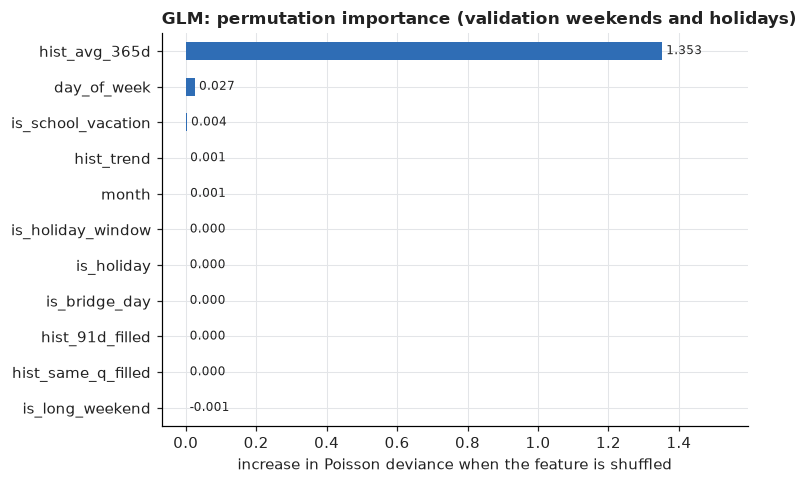

,deviance_increase
hist_avg_365d,1.353
day_of_week,0.026
is_school_vacation,0.004
hist_trend,0.001
month,0.001
is_holiday_window,0.000
is_holiday,0.000
is_bridge_day,0.000
hist_91d_filled,0.000
hist_same_q_filled,0.000


In [102]:
# 4.3.2. Permutation importance of the 8 validation GLMs, each on its own quarter's weekends and holidays
glm_predict = lambda m, X: m.predict(X).to_numpy()
glm_importance = permutation_importance(GLM_FITS, glm_predict, GLM_COLS)
plot_importance(glm_importance, "glm_poisson")
glm_importance.round(4).to_frame()

#### 4.4. Result

- **Stage:** evaluation on the validation quarters (1,170 weekend/holiday rows).
- **Framework:** *Evaluation*.

| Model | MAE | RMSE | Poisson deviance |
|---|---|---|---|
| `baseline_dayoff_365d` | 1.217 | 1.546 | 1.148 |
| **`glm_poisson`** | **1.196** | **1.523** | **1.121** |

- **The GLM beats the baseline on all three metrics**, by about 2% on the Poisson deviance.
- **No overdispersion:** the dispersion is between 1.00 and 1.02 in every quarter, so the Poisson assumption holds and a negative binomial model is not needed. (A negative binomial fit gave the same predictions.)
- **Coefficients** (last fit):
  - `log(hist_avg_365d)`: coef 0.99, so the forecast follows the region's recent level 1-to-1.
  - **Day of week:** Monday to Thursday have 12–24% fewer accidents than Friday; Saturday and Sunday are about the same as Friday.
  - **December** has about 13% more accidents than January. The other months and the holiday features are not significant once the day of week is in the model.
  - `hist_91d_filled` is 0.90: in 2020 Q3 there were about 10% fewer accidents than the filled history suggested (traffic was still recovering from COVID).
- **Tried and dropped:** a fixed effect per region instead of `log(hist_avg_365d)` (Poisson deviance 1.137), and adding the weather columns (no gain).
- **Permutation importance (4.3.2):** the region's level (`hist_avg_365d`) carries almost everything (1.35), then the day of week (0.026). The holiday features are close to 0, as their p-values said.

#### 4.5. Visualise the forecast against the normal level

- **Stage:** evaluation, as charts. No new training: it uses the GLM predictions from 4.1.
- **Framework:** *Evaluation*.
- **What is shown:** the average number of accidents per weekend/holiday day, week by week (weeks end on Sunday). Daily counts per region are mostly 0–5 and too noisy to read. Weekly *totals* would also jump with the number of days off in a week (Carnival weeks have 4), so the charts show the average per day off, and the tables show the quarter totals.
  - **Actual** (dark line): what happened.
  - **GLM forecast** (blue): the rolling forecast from 4.1, each quarter made with data up to its cutoff.
  - **Normal level** (grey, dashed): the baseline, i.e. the average weekend/holiday day of the 365 days before the cutoff. Where the blue line is close to the grey one, the GLM adds little to "a normal quarter".
- **4.5.1** shows all 8 validation quarters for the 5 regions together, with the quarter totals. **4.5.2** zooms into one quarter, per region: the year before the cutoff, the 1-month gap (not known on the forecast day), then the forecast quarter with an 80% range.

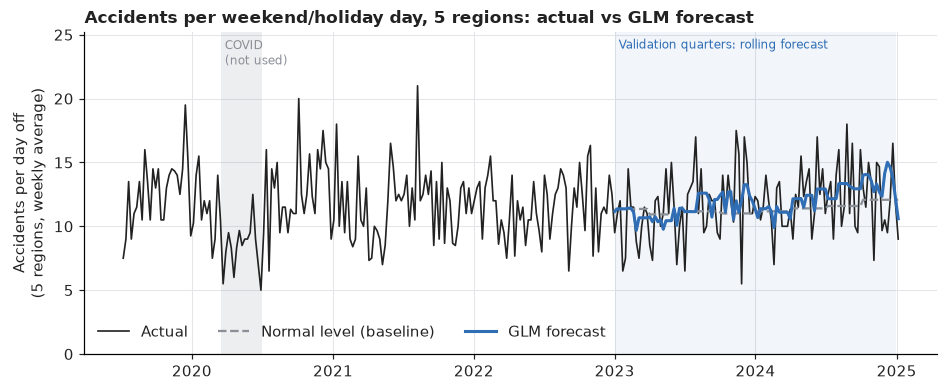

,actual,forecast,baseline,forecast_error_%,baseline_error_%
quarter,,,,,
2023Q1,283,303.700,318.100,7.300,12.400
2023Q2,321,316.800,327.900,-1.300,2.200
2023Q3,327,329.200,312.800,0.700,-4.300
2023Q4,392,370.900,341.300,-5.400,-12.900
2024Q1,335,338.900,346.400,1.200,3.400
2024Q2,351,343.400,319.200,-2.200,-9.000
2024Q3,335,334.000,301.300,-0.300,-10.000
2024Q4,384,425.600,386.500,10.800,0.600


In [103]:
# 4.5.1. Weekly average per weekend/holiday day, 5 regions together: actual vs GLM forecast vs normal level
plot_weekly("glm_poisson")
quarter_totals_table("glm_poisson").round(1)

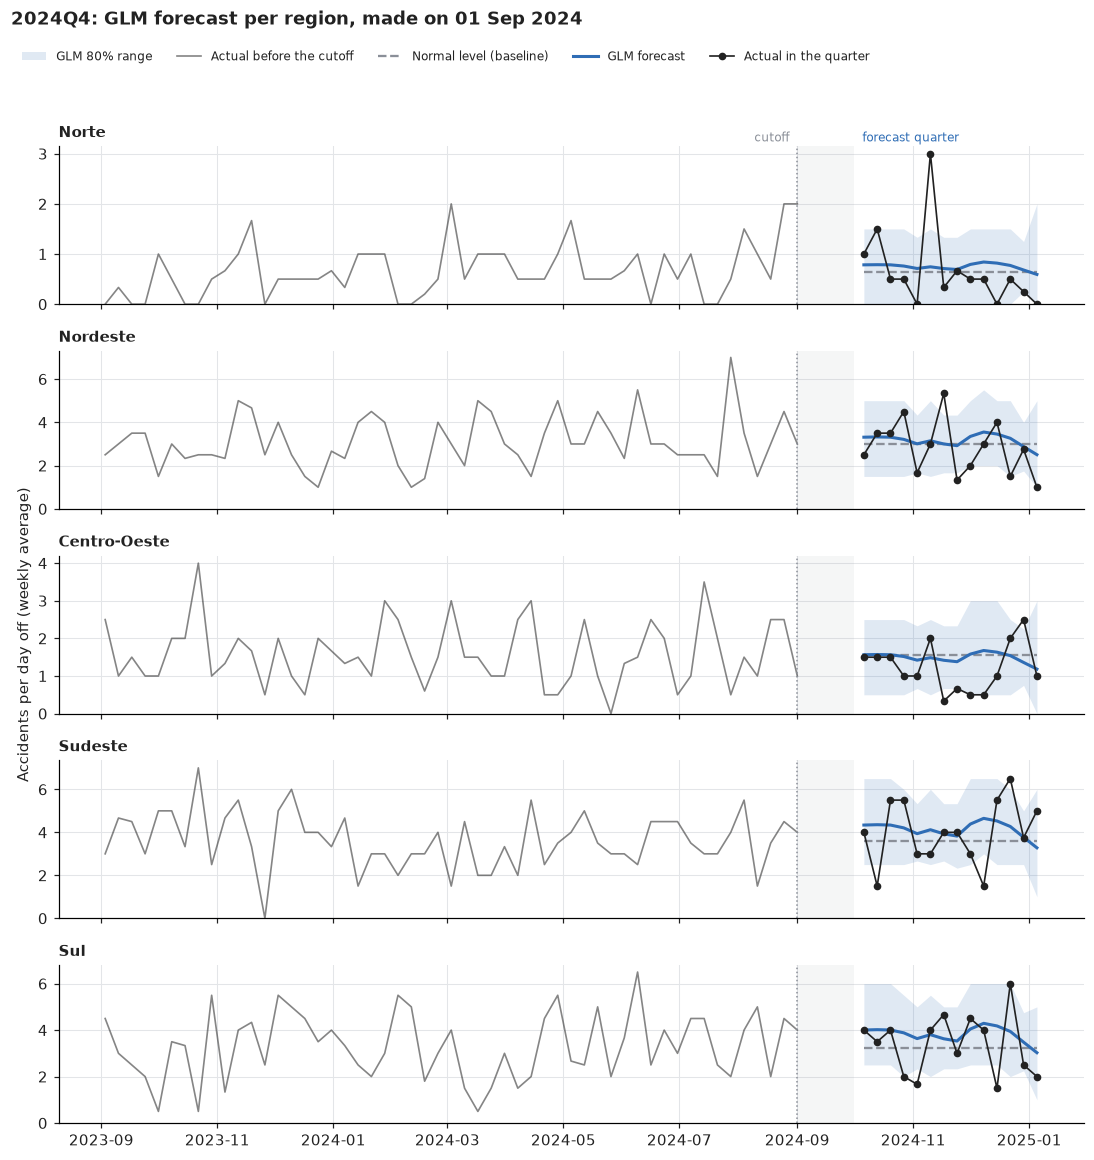

,actual,forecast,baseline,forecast_error_%,baseline_error_%
region,,,,,
Norte,20.000,23.800,20.800,19.200,3.900
Nordeste,92.000,100.700,96.500,9.400,4.900
Centro-Oeste,40.000,47.600,49.500,18.900,23.800
Sudeste,125.000,131.800,115.700,5.500,-7.400
Sul,107.000,121.700,103.900,13.700,-2.900
Total,384.000,425.600,386.500,10.800,0.600


In [104]:
# 4.5.2. One forecast quarter per region: the year before the cutoff, then the forecast with an 80% range
QUARTER = "2024Q4"   # any validation quarter: 2023Q1 ... 2024Q4
plot_quarter_regions("glm_poisson", QUARTER).round(1)

**What the charts show** (validation quarters, weekends and holidays)

| Quarter | Actual | GLM | Baseline | GLM error | Baseline error |
|---|---|---|---|---|---|
| 2023 Q1 | 283 | 304 | 318 | +7% | +12% |
| 2023 Q2 | 321 | 317 | 328 | −1% | +2% |
| 2023 Q3 | 327 | 329 | 313 | +1% | −4% |
| 2023 Q4 | 392 | 371 | 341 | −5% | −13% |
| 2024 Q1 | 335 | 339 | 346 | +1% | +3% |
| 2024 Q2 | 351 | 343 | 319 | −2% | −9% |
| 2024 Q3 | 335 | 334 | 301 | 0% | −10% |
| 2024 Q4 | 384 | 426 | 387 | **+11%** | +1% |

- **The GLM is closer to the actual quarter total than the normal level in 7 of 8 quarters.** In 6 quarters it is within ±5%; the baseline misses by up to 13%.
- **It follows the rises better.** In 2023 Q4 and 2024 Q2–Q3, accidents were above the past year's average. The baseline is an average of the past year, so it stays flat and is 9–13% too low; the GLM, with `hist_trend` and the December effect, is 0–5% too low.
- **2024 Q4 is the exception:** the GLM is 11% too high, in every region, while the baseline is almost exact. The GLM expected the high level of mid-2024 and the usual December increase to continue; accidents fell back instead. Worth watching in the final test (2025).
- **Week to week, the actual values jump around the forecast.** 87% of the weekly values fall inside the 80% range (with whole-number counts the range covers a bit more than 80%), so the range is about right: the GLM gets the level of a quarter, but single weeks are mostly chance, as section 3 expected.
- To look at another quarter, change `QUARTER` in 4.5.2.

#### 4.6. Forecast of the total accidents with injuries or fatalities, per quarter

- **Stage:** evaluation, as charts. No new training: it uses the GLM predictions from 4.1.
- **Framework:** *Evaluation*.
- **What is shown:** the **total** number of accidents with injuries or fatalities (the target: classes 1 and 2) on the weekends and holidays of each quarter. This is the number the planners work with: how many accidents with victims to expect next quarter, to plan ambulances, rescue teams and patrols.
  - **Actual** (dark): every quarter from 2019 Q3, the first training quarter, to 2024 Q4.
  - **GLM forecast** (blue): the 8 validation quarters, each made 1 month before the quarter starts, with an 80% range.
  - **Normal level** (grey, dashed): the baseline over the same quarters.
- The totals depend on how many weekend and holiday days a quarter has (Carnival, Easter), so the line moves from quarter to quarter even when the daily level is the same. The forecast uses the same days, so the comparison is fair.
- **About the 80% range:** it covers only the chance in the counts (Poisson), not an error in the level the GLM predicts. A quarter can fall outside it when the level is wrong (see 2024 Q4).

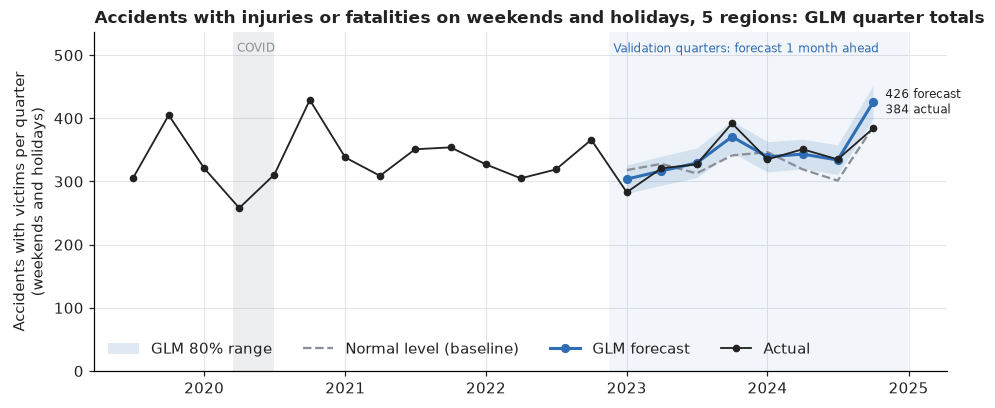

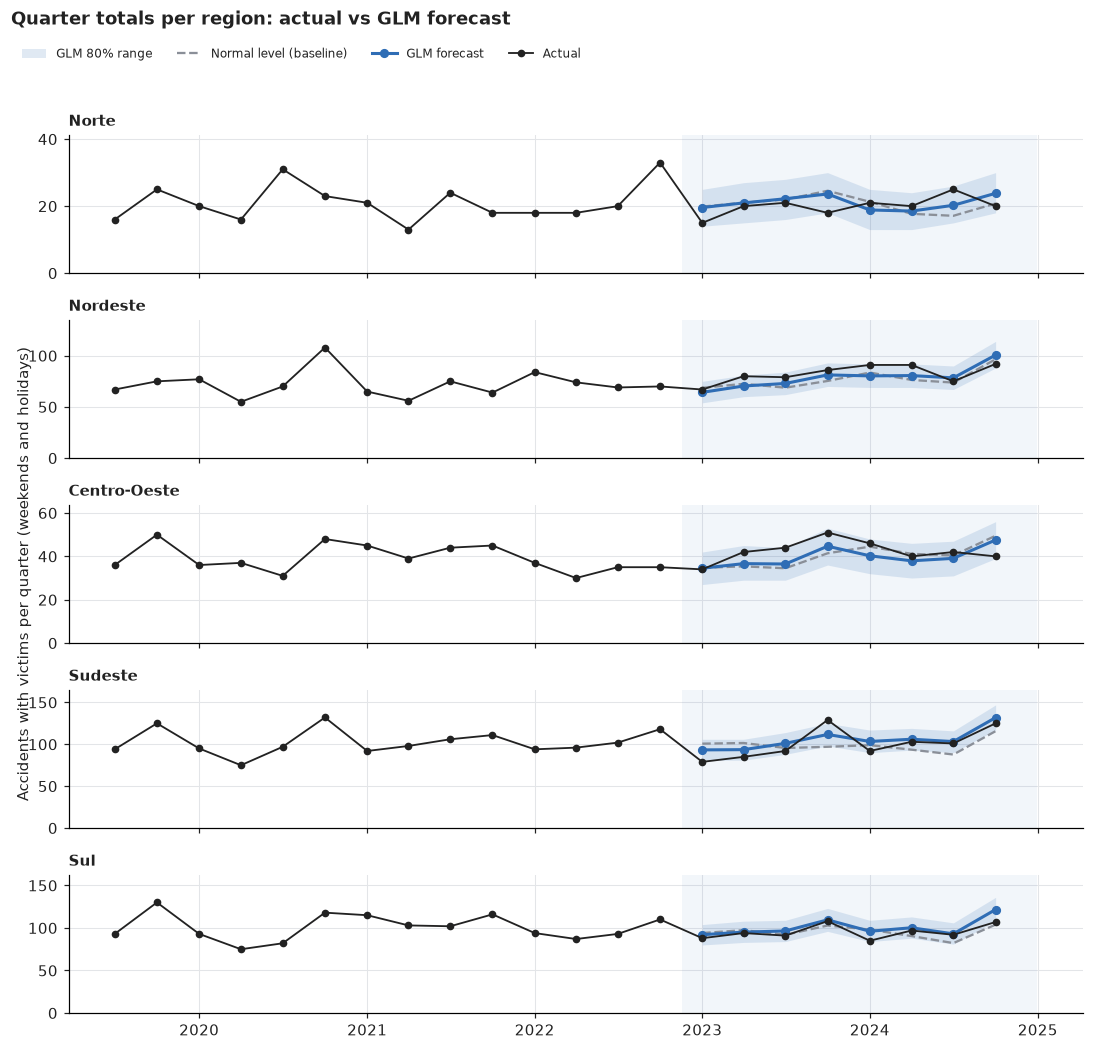

In [105]:
# 4.6.1. Quarter totals of accidents with injuries or fatalities on weekends and holidays: history, then the GLM forecast
plot_quarter_totals("glm_poisson")

In [106]:
# 4.6.2. How far the quarter totals are from the actual, per region (average over the 8 validation quarters)
region_errors_table("glm_poisson").round(1)

,actual_per_quarter,forecast_per_quarter,forecast_avg_miss_%,baseline_avg_miss_%,quarters_inside_80%_range
Norte,20.000,21.000,16.000,15.900,8.000
Nordeste,82.600,78.600,8.300,8.500,8.000
Centro-Oeste,42.400,39.600,10.900,11.500,8.000
Sudeste,100.800,105.500,9.300,14.100,6.000
Sul,95.200,100.500,5.600,6.500,7.000
Total,341.000,345.300,3.600,6.900,7.000


(total accidents with injuries or fatalities, weekends and holidays)

| Region | Actual per quarter | GLM average miss | Baseline average miss | Quarters inside the 80% range |
|---|---|---|---|---|
| Norte | 20 | 16% | 16% | 8 of 8 |
| Nordeste | 83 | 8% | 9% | 8 of 8 |
| Centro-Oeste | 42 | 11% | 12% | 8 of 8 |
| Sudeste | 101 | 9% | 14% | 6 of 8 |
| Sul | 95 | 6% | 7% | 7 of 8 |
| **5 regions** | **341** | **4%** | **7%** | **7 of 8** |

- **Q4 is the busiest quarter almost every year** (405 in 2019, 429 in 2020, 392 in 2023, 384 in 2024): it has more holidays and the December traffic. Both forecasts rise in Q4 because they cover more days off; the GLM also adds its December effect.
- **For the 5 regions together, the GLM misses the quarter total by 4% on average (about 12 accidents), the normal level by 7%.** 7 of the 8 quarters fall inside the 80% range; only 2024 Q4 does not (426 forecast, 384 actual).
- **Per region the misses are bigger**, because some errors cancel out when the regions are added up. The smaller the region, the bigger the miss in %: Norte has about 20 accidents a quarter, so a miss of 3 accidents is already 16%, for the GLM and the baseline alike. That is mostly chance.
- **The GLM gains most where the level moves:** in Sudeste it misses by 9% on average, against 14% for the baseline.
- **For the planners:** plan each region with the 80% range rather than the single number, especially in the small regions (Norte, Centro-Oeste).

--------
## 5. Model 2 - XGBoost

**1. Representation**

$\log \mu = f_1(x) + f_2(x) + \dots + f_K(x)$: a sum of $K$ small regression trees on the log scale. The prediction is $e^{\text{sum}}$, so it is always positive, like the GLM.
- It uses all the `FEATURES` (section 2.4), and handles the empty `days_to_holiday` / `days_after_holiday` values itself.
- Unlike the GLM, the trees find interactions and non-linear effects on their own. The tree depth limits how many features can interact: depth 2 means pairs of features.

**2. Evaluation**

- **Training:** the Poisson loss (`objective="count:poisson"`), the same loss as the GLM.
- **Tuning and selection:** the Poisson deviance on the weekend/holiday rows of the validation quarters.

**3. Optimisation**

- **Trees:** gradient boosting. Each new tree is fitted to the errors (gradients of the loss) of the trees before it, and added with a small weight (learning rate 0.03). Each tree sees a random 80% of the rows and columns; `random_state=42` makes this repeatable.
- **Settings:** a grid search on the validation quarters over tree depth and number of trees (5.1). The validation score of the chosen settings is therefore a bit optimistic; the final test (section 9) gives the honest score.

#### 5.1. Tune

- **Stage:** tuning. 8 settings: tree depth (2, 3, 4, 6) × number of trees (300, 600). The other settings are fixed: learning rate 0.03, 80% of the rows and columns per tree, at least 5 rows per leaf.
- **Framework:** *Optimisation* at the outer level: a search over the settings, judged by the *Evaluation* metric (Poisson deviance).
- **How:** each setting runs the full rolling backtest (8 settings × 8 quarters = 64 models, about 30 seconds) and is scored on the weekend/holiday validation rows.
- **Choice:** the setting with the lowest Poisson deviance.
- **Note:** the validation quarters are used both to choose the settings and to score them, so the score of the chosen setting is a bit optimistic. The final test (section 9) gives the honest score.

In [107]:
# 5.1. Tune XGBoost on the validation quarters: tree depth x number of trees
def make_xgb(max_depth, n_estimators, learning_rate=0.03):
    def fit_predict(X_tr, y_tr, X_te):
        m = XGBRegressor(objective="count:poisson", max_depth=max_depth, n_estimators=n_estimators,
                         learning_rate=learning_rate, subsample=0.8, colsample_bytree=0.8,
                         min_child_weight=5, random_state=42, n_jobs=-1)
        XGB_FITS.append(m.fit(X_tr, y_tr))
        return m.predict(X_te)
    return fit_predict

XGB_GRID = [{"max_depth": d, "n_estimators": n} for d in [2, 3, 4, 6] for n in [300, 600]]
xgb_runs = {}
for params in XGB_GRID:
    XGB_FITS = []
    xgb_runs[(params["max_depth"], params["n_estimators"])] = (backtest(make_xgb(**params), FEATURES), XGB_FITS)

xgb_tuning = score_table({k: v[0] for k, v in xgb_runs.items()}).droplevel(1)
xgb_tuning.index = pd.MultiIndex.from_tuples(xgb_tuning.index, names=["max_depth", "n_estimators"])
xgb_tuning.sort_values("Poisson_dev")

MAE  RMSE  Poisson_dev  n_rows
max_depth n_estimators                                 
2         300          1.203 1.527        1.128    1170
          600          1.199 1.526        1.129    1170
3         300          1.201 1.527        1.130    1170
          600          1.199 1.530        1.135    1170
4         300          1.201 1.532        1.138    1170
          600          1.203 1.539        1.149    1170
6         300          1.207 1.546        1.159    1170
          600          1.213 1.559        1.183    1170

#### 5.2. Train with the chosen settings and look at feature importance

- **Stage:** training (with the chosen settings) + interpretation. The backtest of the best setting already ran in 5.1, so its predictions and its 8 models are reused here, not trained again.
- **Framework:** the result of the *Optimisation*, plus interpretation.
- **Output:** `PREDS["xgboost"]`, and the 8 fitted models in `XGB_FITS`.
- **Feature importance**, two views:
  - **5.2 (gain)** of the last model (trained up to 1 Sep 2024): how much a feature improves the loss when the trees use it, as a share of the total.
  - **5.2.2 (permutation importance)** of all 8 models, each on the weekends and holidays of the quarter it forecast: the same measure as for the GLM (4.3.2) and the Random Forest (6.3).
- The final test (section 9) trains the same settings again, on the data before each test quarter's cutoff.

In [108]:
# 5.2. Keep the best settings (lowest Poisson deviance) and look at the feature importance of its last fit
best = xgb_tuning["Poisson_dev"].idxmin()
PREDS["xgboost"], XGB_FITS = xgb_runs[best]
print("Best settings: max_depth = %d, n_estimators = %d" % best)
display(score_table({k: PREDS[k] for k in ["baseline_dayoff_365d", "glm_poisson", "xgboost"]}))

# Gain = how much each feature improves the loss when the trees use it
importance = pd.Series(XGB_FITS[-1].get_booster().get_score(importance_type="gain"), name="gain")
(importance / importance.sum()).sort_values(ascending=False).head(15).round(3).to_frame()

Best settings: max_depth = 2, n_estimators = 300


,,MAE,RMSE,Poisson_dev,n_rows
model,,,,,
baseline_dayoff_365d,all,1.217,1.546,1.148,1170
glm_poisson,all,1.196,1.523,1.121,1170
xgboost,all,1.203,1.527,1.128,1170


,gain
hist_avg_91d,0.351
hist_avg_365d,0.199
region_Nordeste,0.131
hist_dayoff_avg_365d,0.073
region_Centro-Oeste,0.055
region_Norte,0.052
hist_same_q_last_year,0.038
dow,0.021
is_weekend,0.010
region_Sudeste,0.009


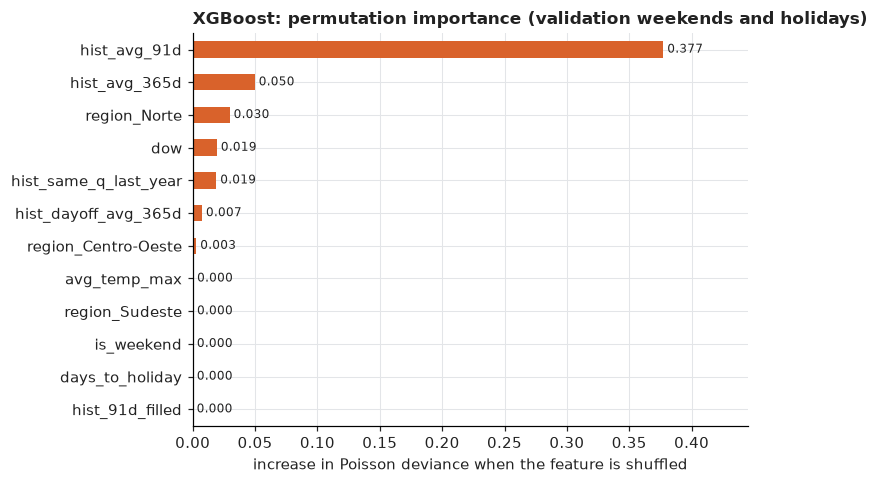

,deviance_increase
hist_avg_91d,0.377
hist_avg_365d,0.050
region_Norte,0.030
dow,0.019
hist_same_q_last_year,0.019
hist_dayoff_avg_365d,0.007
region_Centro-Oeste,0.003
avg_temp_max,0.000
region_Sudeste,0.000
is_weekend,0.000


In [109]:
# 5.2.2. Permutation importance of the 8 validation XGBoost models, each on its own quarter's weekends and holidays
xgb_predict = lambda m, X: m.predict(X)
xgb_importance = permutation_importance(XGB_FITS, xgb_predict, FEATURES)
plot_importance(xgb_importance, "xgboost")
xgb_importance.head(12).round(4).to_frame()

#### 5.3. Result

- **Stage:** evaluation on the validation quarters (1,170 weekend/holiday rows).
- **Framework:** *Evaluation*.

| Model | MAE | RMSE | Poisson deviance |
|---|---|---|---|
| `baseline_dayoff_365d` | 1.217 | 1.546 | 1.148 |
| **`glm_poisson`** | **1.196** | **1.523** | **1.121** |
| `xgboost` (depth 2, 300 trees) | 1.203 | 1.527 | 1.128 |

- **Shallow trees win.** Depth 2 is best; depth 6 is worse than the baseline (Poisson deviance 1.159–1.183). The signal is mostly the region's level and the day of week, and deeper trees start fitting noise.
- **XGBoost beats the baseline, but not the GLM.** With this little signal, the simpler model is as good or better.
- **Feature importance** (share of gain, last fit): the history features about 66% (`hist_avg_91d` 35%, `hist_avg_365d` 20%), the region columns about 25%, day of week and weekend about 3%, each weather column below 1%. The same story as the GLM: the recent level of each region carries most of the information.
- Depth 2 is the smallest depth tried. A depth-1 model could be tried too, but the gain would be small.
- **Permutation importance (5.2.2):** the 91-day level (`hist_avg_91d`, 0.38) is far ahead of the 365-day level (0.05), then the region columns and the day of week (about 0.02). The weather and holiday features are close to 0. XGBoost leans on the recent 91-day level; the GLM on the 365-day level.

#### 5.4. Visualise the forecast against the normal level

- **Stage:** evaluation, as charts. No new training: it uses the XGBoost predictions from 5.2.
- **Framework:** *Evaluation*.
- **What is shown:** the same charts and tables as for the GLM in 4.5 (functions from section 2.5), so the two models can be compared directly.
  - **5.4.1:** the weekly average per weekend/holiday day, 5 regions, over the 8 validation quarters, with the quarter totals.
  - **5.4.2:** one quarter per region: the year before the cutoff, the 1-month gap, then the forecast with an 80% range. Change `QUARTER` to look at another quarter.

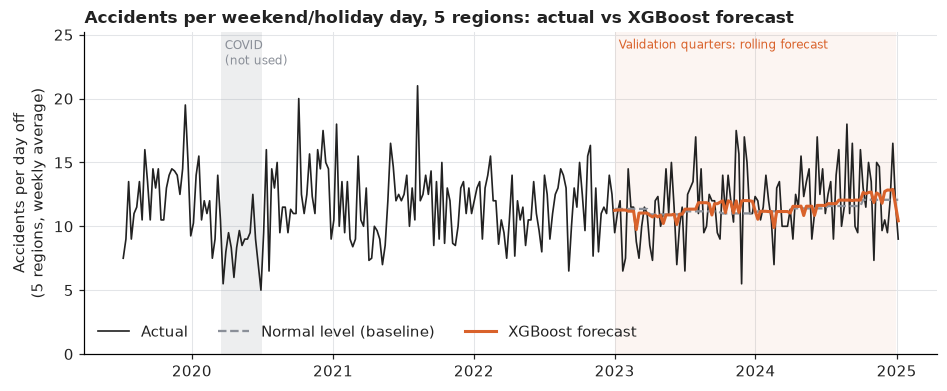

,actual,forecast,baseline,forecast_error_%,baseline_error_%
quarter,,,,,
2023Q1,283,305.500,318.100,8.000,12.400
2023Q2,321,321.700,327.900,0.200,2.200
2023Q3,327,323.300,312.800,-1.100,-4.300
2023Q4,392,361.000,341.300,-7.900,-12.900
2024Q1,335,337.500,346.400,0.700,3.400
2024Q2,351,320.200,319.200,-8.800,-9.000
2024Q3,335,311.000,301.300,-7.200,-10.000
2024Q4,384,394.300,386.500,2.700,0.600


In [110]:
# 5.4.1. Weekly average per weekend/holiday day, 5 regions together: actual vs XGBoost forecast vs normal level
plot_weekly("xgboost")
quarter_totals_table("xgboost").round(1)

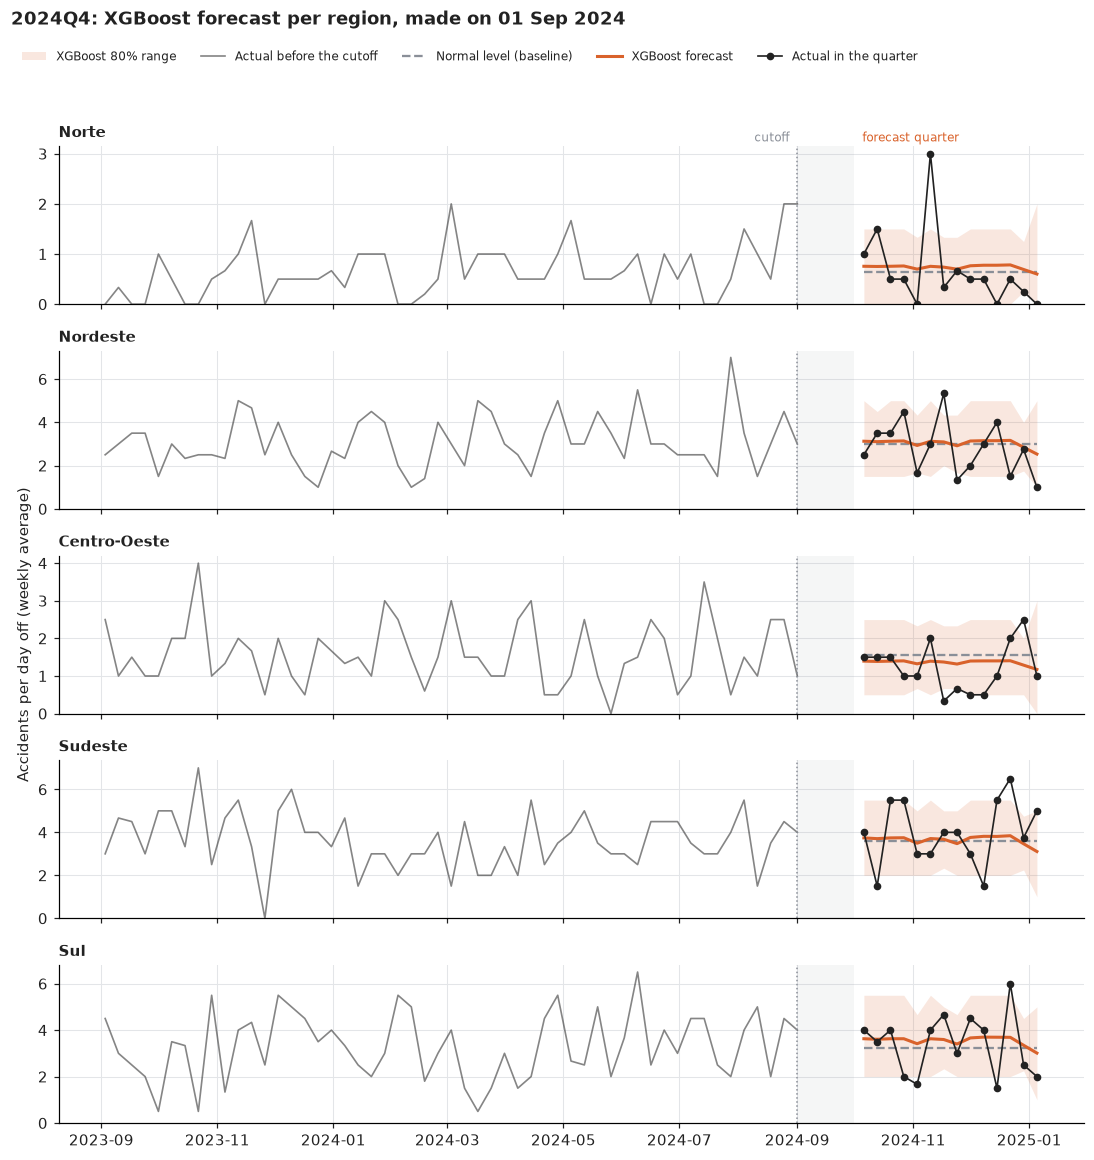

,actual,forecast,baseline,forecast_error_%,baseline_error_%
region,,,,,
Norte,20.000,23.500,20.800,17.700,3.900
Nordeste,92.000,97.200,96.500,5.700,4.900
Centro-Oeste,40.000,43.500,49.500,8.800,23.800
Sudeste,125.000,116.700,115.700,-6.700,-7.400
Sul,107.000,113.400,103.900,5.900,-2.900
Total,384.000,394.300,386.500,2.700,0.600


In [111]:
# 5.4.2. One forecast quarter per region: the year before the cutoff, then the forecast with an 80% range
QUARTER = "2024Q4"   # any validation quarter: 2023Q1 ... 2024Q4
plot_quarter_regions("xgboost", QUARTER).round(1)

**What the charts show** (validation quarters, weekends and holidays; the GLM from 4.5 for comparison)

| Quarter | Actual | XGBoost | Baseline | XGBoost error | Baseline error | GLM error |
|---|---|---|---|---|---|---|
| 2023 Q1 | 283 | 306 | 318 | +8% | +12% | +7% |
| 2023 Q2 | 321 | 322 | 328 | 0% | +2% | −1% |
| 2023 Q3 | 327 | 323 | 313 | −1% | −4% | +1% |
| 2023 Q4 | 392 | 361 | 341 | −8% | −13% | −5% |
| 2024 Q1 | 335 | 338 | 346 | +1% | +3% | +1% |
| 2024 Q2 | 351 | 320 | 319 | −9% | −9% | −2% |
| 2024 Q3 | 335 | 311 | 301 | −7% | −10% | 0% |
| 2024 Q4 | 384 | 394 | 387 | +3% | +1% | +11% |

- **XGBoost is closer to the actual quarter total than the normal level in 7 of 8 quarters**, like the GLM.
- **It follows the rises less than the GLM.** In 2023 Q4 and 2024 Q2–Q3 it is 7–9% too low (the GLM 0–5%): it stays closer to the normal level.
- **In 2024 Q4 it does better than the GLM** (+3% against +11%), for the same reason: it did not carry the high level of mid-2024 into the quarter. In that quarter it is too high in Norte (+18%) and Centro-Oeste (+9%) and too low in Sudeste (−7%).

#### 5.5. Forecast of the total accidents with injuries or fatalities, per quarter

- **Stage:** evaluation, as charts. No new training: it uses the XGBoost predictions from 5.2.
- **Framework:** *Evaluation*.
- **What is shown:** the same as for the GLM in 4.6: the **total** number of accidents with injuries or fatalities on the weekends and holidays of each quarter, the number the planners work with.
  - **5.5.1:** every quarter from 2019 Q3, then the XGBoost forecast for the 8 validation quarters with an 80% range: 5 regions together, then per region.
  - **5.5.2:** the average miss per region, and in how many quarters the actual falls inside the 80% range.
- **About the 80% range:** it covers only the chance in the counts (Poisson), not an error in the level the model predicts.

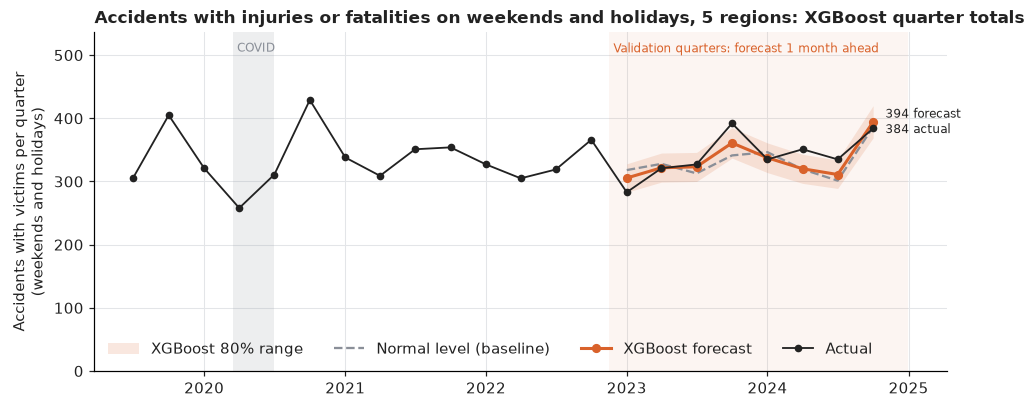

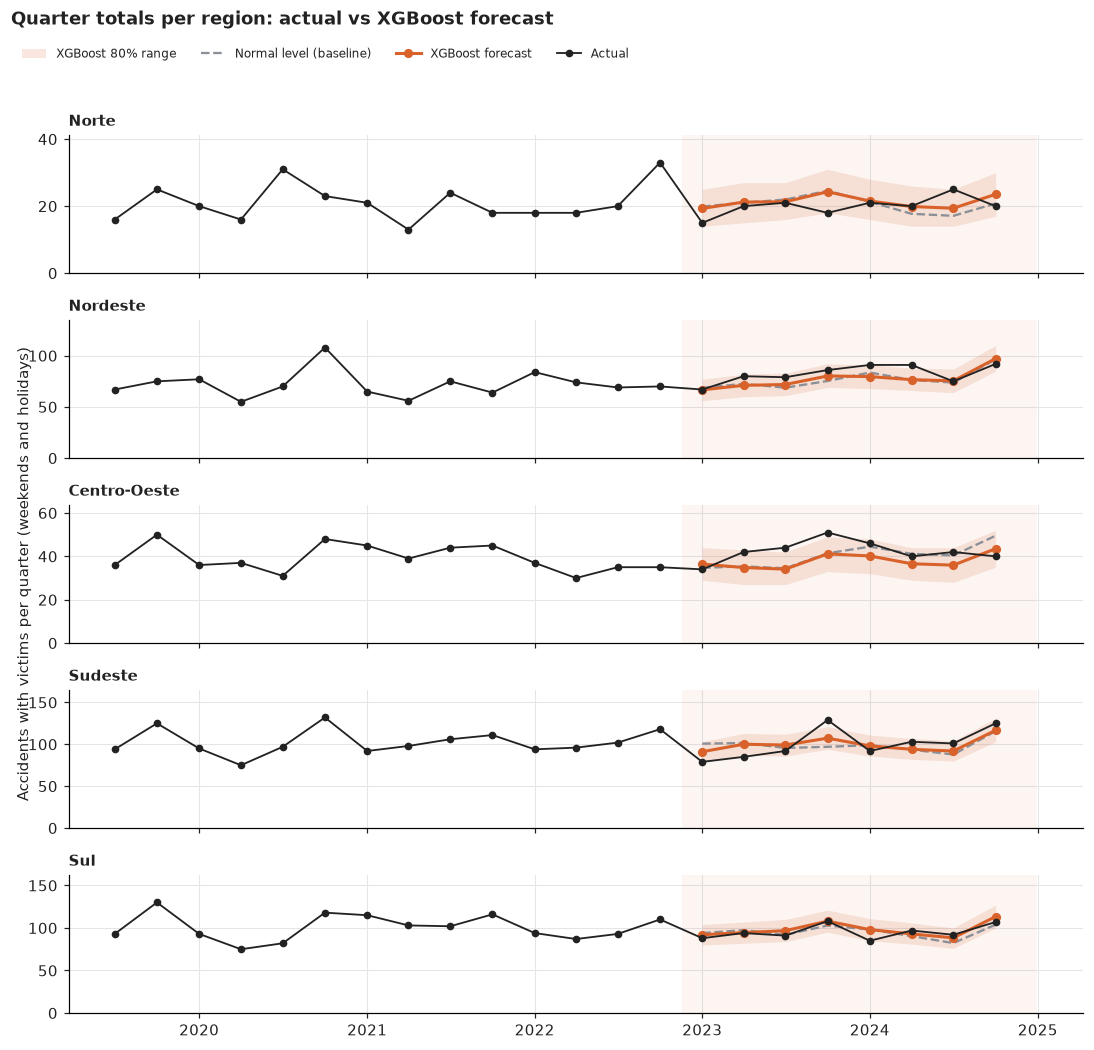

In [112]:
# 5.5.1. Quarter totals of accidents with injuries or fatalities on weekends and holidays: history, then the XGBoost forecast
plot_quarter_totals("xgboost")

In [113]:
# 5.5.2. How far the quarter totals are from the actual, per region (average over the 8 validation quarters)
region_errors_table("xgboost").round(1)

,actual_per_quarter,forecast_per_quarter,forecast_avg_miss_%,baseline_avg_miss_%,quarters_inside_80%_range
Norte,20.000,21.300,14.300,15.900,8.000
Nordeste,82.600,77.300,7.700,8.500,7.000
Centro-Oeste,42.400,37.800,13.800,11.500,6.000
Sudeste,100.800,99.800,11.100,14.100,6.000
Sul,95.200,98.000,5.100,6.500,8.000
Total,341.000,334.300,4.600,6.900,5.000


**What the charts show** (quarter totals, weekends and holidays, 8 validation quarters)

| Region | Actual per quarter | XGBoost average miss | GLM average miss | Baseline average miss | XGBoost: quarters inside the 80% range |
|---|---|---|---|---|---|
| Norte | 20 | 14% | 16% | 16% | 8 of 8 |
| Nordeste | 83 | 8% | 8% | 9% | 7 of 8 |
| Centro-Oeste | 42 | 14% | 11% | 12% | 6 of 8 |
| Sudeste | 101 | 11% | 9% | 14% | 6 of 8 |
| Sul | 95 | 5% | 6% | 7% | 8 of 8 |
| **5 regions** | **341** | **5%** | **4%** | **7%** | **5 of 8** |

- **For the 5 regions together, XGBoost misses the quarter total by 4.6% on average**, the GLM by 3.6% and the baseline by 6.9%.
- **Only 5 of 8 quarters fall inside the 80% range** (the GLM: 7 of 8). The three misses are 2023 Q4, 2024 Q2 and 2024 Q3, the quarters where accidents rose and XGBoost stayed too low.
- **Per region:** XGBoost is better than the GLM in Norte and Sul, worse in Centro-Oeste and Sudeste.
- **Same conclusion as 5.3:** XGBoost beats the normal level, but not the GLM.

--------
## 6. Model 3 - Random Forest

**1. Representation:** $\mu$ = the average of many regression trees, each grown on a bootstrap sample of the training days, with a random share of the features tried at each split. It uses the same `FEATURES` as XGBoost (section 2.4). The chosen version learns the **ratio** `accidents / hist_avg_365d` and multiplies the prediction back by the region's level at the cutoff, because trees cannot predict outside the range they saw in training (details below).

**2. Evaluation:** in training, each split is chosen to reduce the Poisson deviance (`criterion="poisson"`). Selection uses the Poisson deviance on the weekend/holiday rows of the validation quarters, like the other models.

**3. Optimisation:** each tree is grown greedily (the best split at each step), and averaging many trees reduces the variance of single trees. The settings are tuned on the validation quarters: minimum rows per leaf × share of features per split (6.1); then the target, count or ratio, is chosen (6.2).

`RandomForestRegressor(criterion="poisson")`:

Poisson criterion, so the trees split on the loss made for counts. It uses the same `FEATURES` (section 2.4) and the same `backtest()` as XGBoost, so all models are scored on exactly the same rows.

**Two choices specific to the Random Forest:**
- **Empty `days_to_holiday` / `days_after_holiday`** mean "no holiday within 3 days". That is information, not a missing value, so they are coded as **4** ("more than 3 days away"). Filling with the mean (≈1.4) would put every normal day 1 day from a holiday.
- **Target as a ratio to the region's level.** Trees cannot predict outside the range of values they saw in training, so a rising region would be under-forecast. The forest learns `accidents / hist_avg_365d` (e.g. "a long weekend is 1.15× the usual level"), and the prediction is multiplied back by the level known at the cutoff. Both versions are compared below.

#### 6.1. Tune

- **Stage:** tuning. 6 settings: minimum rows per leaf (5, 20, 50) × share of features tried at each split (0.33, 0.6), with 200 trees and the direct count target.
- **Framework:** *Optimisation* at the outer level: a search over the settings, judged by the *Evaluation* metric (Poisson deviance).
- **How:** each setting runs the full rolling backtest (6 settings × 8 quarters = 48 forests, about 1–2 minutes) and is scored on the weekend/holiday validation rows.
- **Choice:** the setting with the lowest Poisson deviance. The settings are tuned with the direct count target; the target itself is chosen in 6.2. As for XGBoost, the validation score of the chosen setting is a bit optimistic; the final test (section 9) gives the honest score.

In [114]:
# 6.1. Tune the Random Forest on the validation quarters: leaf size x features per split
def prepare_rf(X):
    """Empty days_to/after_holiday = no holiday within 3 days -> coded as 4."""
    return X.fillna({"days_to_holiday": 4, "days_after_holiday": 4})

def make_rf(min_samples_leaf, max_features, n_estimators=200, target="count"):
    def fit_predict(X_tr, y_tr, X_te):
        m = RandomForestRegressor(n_estimators=n_estimators, criterion="poisson", min_samples_leaf=min_samples_leaf,
                                  max_features=max_features, n_jobs=-1, random_state=42)
        if target == "ratio":   # learn accidents relative to the region's level known at the cutoff
            m.fit(prepare_rf(X_tr), y_tr / X_tr["hist_avg_365d"])
            pred = m.predict(prepare_rf(X_te)) * X_te["hist_avg_365d"].to_numpy()
        else:
            m.fit(prepare_rf(X_tr), y_tr)
            pred = m.predict(prepare_rf(X_te))
        RF_FITS.append(m)
        return pred
    return fit_predict

RF_GRID = [{"min_samples_leaf": l, "max_features": f} for l in [5, 20, 50] for f in [0.33, 0.6]]
rf_runs = {}
for params in RF_GRID:
    RF_FITS = []
    rf_runs[(params["min_samples_leaf"], params["max_features"])] = backtest(make_rf(**params), FEATURES)

rf_tuning = score_table(rf_runs).droplevel(1)
rf_tuning.index = pd.MultiIndex.from_tuples(rf_tuning.index, names=["min_samples_leaf", "max_features"])
rf_tuning.sort_values("Poisson_dev")

MAE  RMSE  Poisson_dev  n_rows
min_samples_leaf max_features                                 
50               0.600        1.207 1.535        1.133    1170
                 0.330        1.207 1.535        1.134    1170
20               0.600        1.205 1.536        1.137    1170
                 0.330        1.206 1.538        1.139    1170
5                0.330        1.207 1.546        1.155    1170
                 0.600        1.213 1.551        1.162    1170

#### 6.2. Count or ratio target, with the chosen settings

- **Stage:** training (chosen settings, 500 trees) + comparison of the two targets on the validation quarters.
- **Framework:** *Optimisation* (fit the forests with the chosen settings), then the *Evaluation* of the two targets.
- **Output:** `PREDS["random_forest"]` (the target with the lower Poisson deviance), and the 8 fitted forests in `RF_FITS`.

In [115]:
# 6.2. Chosen settings, 500 trees: direct count vs ratio to the region's level
best_rf = rf_tuning["Poisson_dev"].idxmin()
print("Best settings: min_samples_leaf = %d, max_features = %.2f" % best_rf)
rf_target_runs, rf_target_fits = {}, {}
for target in ["count", "ratio"]:
    RF_FITS = []
    rf_target_runs[f"random_forest_{target}"] = backtest(
        make_rf(*best_rf, n_estimators=500, target=target), FEATURES)
    rf_target_fits[target] = RF_FITS
display(score_table({**{k: PREDS[k] for k in ["baseline_dayoff_365d", "glm_poisson", "xgboost"]}, **rf_target_runs}))

RF_TARGET = min(["count", "ratio"],
                key=lambda t: score_table({t: rf_target_runs[f"random_forest_{t}"]})["Poisson_dev"].iloc[0])
PREDS["random_forest"], RF_FITS = rf_target_runs[f"random_forest_{RF_TARGET}"], rf_target_fits[RF_TARGET]
print("Chosen target:", RF_TARGET)

Best settings: min_samples_leaf = 50, max_features = 0.60


,,MAE,RMSE,Poisson_dev,n_rows
model,,,,,
baseline_dayoff_365d,all,1.217,1.546,1.148,1170
glm_poisson,all,1.196,1.523,1.121,1170
xgboost,all,1.203,1.527,1.128,1170
random_forest_count,all,1.208,1.535,1.133,1170
random_forest_ratio,all,1.197,1.528,1.130,1170


Chosen target: ratio


#### 6.3. Feature importance

- **Stage:** interpretation. No new training: the 8 forests from 6.2, each on its own validation quarter.
- **Framework:** back to the *Representation*: which features the forests use.
- **How:** permutation importance: shuffle one feature at a time and measure how much the Poisson deviance gets worse. Each of the 8 forests is scored **only on the weekend/holiday days of the quarter it forecast**, which it never saw in training (the cell checks this with an `assert`). The 2025 test quarters are not used here.
- **Note on the ratio target:** the region's level (`hist_avg_365d`) also multiplies the prediction, and that part is not shuffled here. So this chart shows what drives the *ratio* (the day-to-day pattern around the level); the level itself is the biggest driver of the count, as in the GLM (coef 0.99).

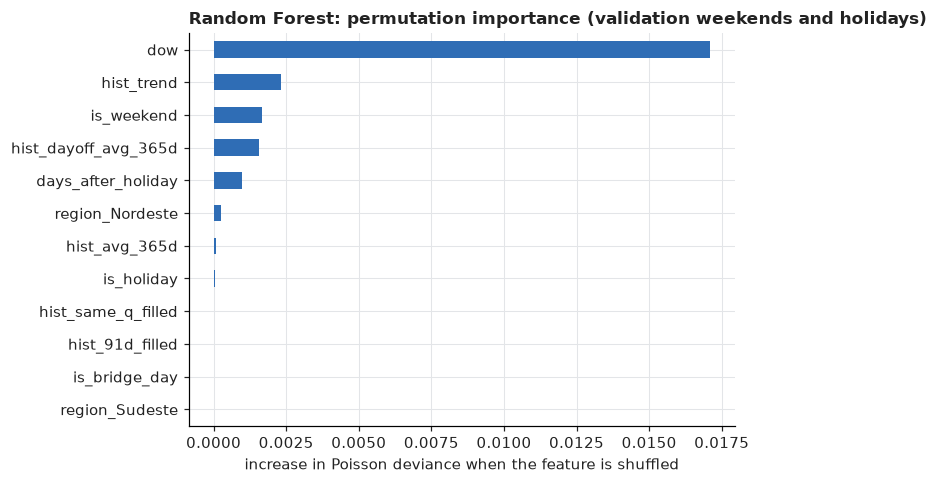

,deviance_increase
dow,0.017
hist_trend,0.002
is_weekend,0.002
hist_dayoff_avg_365d,0.002
days_after_holiday,0.001
region_Nordeste,0.000
hist_avg_365d,0.000
is_holiday,0.000
hist_same_q_filled,-0.000
hist_91d_filled,-0.000


In [116]:
# 6.3. Permutation importance of the 8 validation forests, each on its OWN quarter's weekends and holidays
def rf_permutation_importance(forests, n_repeats=5, seed=42):
    """Shuffle one feature at a time and measure how much the Poisson deviance gets worse.
    Each forest is scored only on the quarter it forecast, never on rows it was trained on."""
    rng = np.random.default_rng(seed)
    val_periods = periods[periods["role"] == "validation"]
    assert len(forests) == len(val_periods), "one forest per validation quarter expected"
    worse = {col: [] for col in FEATURES}
    for q, forest in zip(val_periods.itertuples(), forests):
        X_tr, _, X_q, y_q = split_period(q, FEATURES)
        # out-of-sample check: every training day is before the cutoff, every scored day is in the quarter
        assert model_table.loc[X_tr.index, "date"].max() < q.cutoff < q.q_start <= model_table.loc[X_q.index, "date"].min()
        off = ((X_q["is_weekend"] == 1) | (X_q["is_holiday"] == 1)).to_numpy()
        X_q, y_q = X_q[off], y_q[off].to_numpy()
        level = X_q["hist_avg_365d"].to_numpy() if RF_TARGET == "ratio" else 1.0
        predict = lambda X: np.clip(forest.predict(prepare_rf(X)) * level, 1e-6, None)
        base_dev = mean_poisson_deviance(y_q, predict(X_q))
        for col in FEATURES:
            for _ in range(n_repeats):
                X_perm = X_q.copy()
                X_perm[col] = rng.permutation(X_perm[col].to_numpy())
                worse[col].append(mean_poisson_deviance(y_q, predict(X_perm)) - base_dev)
    return pd.Series({c: np.mean(v) for c, v in worse.items()}, name="deviance_increase").sort_values(ascending=False)

rf_importance = rf_permutation_importance(RF_FITS)

ax = rf_importance.head(12)[::-1].plot.barh(color=BLUE, figsize=(7, 4.5))
ax.set(title="Random Forest: permutation importance (validation weekends and holidays)",
       xlabel="increase in Poisson deviance when the feature is shuffled")
plt.tight_layout(); plt.show()
rf_importance.head(12).round(4).to_frame()

#### 6.4. Result

- **Stage:** evaluation on the validation quarters (1,170 weekend/holiday rows).
- **Framework:** *Evaluation*.

| Model | MAE | RMSE | Poisson deviance |
|---|---|---|---|
| `baseline_dayoff_365d` | 1.217 | 1.546 | 1.148 |
| **`glm_poisson`** | **1.196** | **1.523** | **1.121** |
| `xgboost` (depth 2, 300 trees) | 1.203 | 1.527 | 1.128 |
| `random_forest`, count target | 1.208 | 1.535 | 1.133 |
| `random_forest`, ratio target (chosen) | 1.197 | 1.528 | 1.130 |

- **Large leaves win.** Leaves of 20–50 rows are within 0.006 Poisson deviance of each other; leaves of 5 rows are clearly worse (1.155–1.162), because small leaves fit the day-to-day noise. The same lesson as the shallow trees in XGBoost.
- **The ratio target helps a little**, because the forest can then follow a region whose level moves (trees cannot extrapolate).
- **Random Forest beats the baseline, ties with XGBoost, and does not beat the GLM.** With this little signal, the simplest model with the right structure (log link, level 1-to-1) is as good as or better than the forests.
- **Importance:** around the region's level, the **day of week** is by far the strongest pattern (Monday–Thursday lower), then `hist_trend`, `is_weekend` and the weekend/holiday history. The holiday features (`is_holiday`, bridge day, long weekend) are close to zero, as in the GLM, where they are not significant once the day of week is in the model.
- **Noise floor:** a region has ~2.3 accidents per weekend/holiday day. Even a perfect forecast of the daily rate would have an MAE of ~1.18 and an RMSE of ~1.53 (Poisson). All models sit within 2% of that floor, so most of the remaining error is chance, not missed signal.

--------
## 7. Comparison

All models on exactly the same rows: the weekend/holiday days of the 8 validation quarters (2023–2024), each forecast 1 month before the quarter starts.

- **Framework:** *Evaluation* only. Nothing is trained or tuned here: the models come from sections 3–6.
- **Main metric:** the Poisson deviance (section 2.3). The tables also show MAE and RMSE, and every score as **% better than the baseline** (higher is better), because the differences between models are small.

| Step | Question |
|---|---|
| 7.1 | How does each model score? |
| 7.2 | How much better than the baseline is each model, per metric? |
| 7.3 | Is the gain stable from quarter to quarter? |
| 7.4 | In which regions does each model gain? |
| 7.5 | What do the planners see: the quarter totals? |
| 7.6 | Result |

#### 7.1. Scores of all models

- **Stage:** evaluation. `compare_table()` scores every model on the same rows and adds the gain over the baseline.
- **Framework:** *Evaluation*.
- **Two tables:** weekends and holidays (the main score), then all days (extra). The baseline is built for days off, so it is weaker on weekdays; that makes the all-days gains look bigger.

In [117]:
# 7.1. All models on the validation quarters: scores and gain over the baseline (in %, higher is better)
COMPARE = ["baseline_dayoff_365d"] + MODELS

def compare_table(preds, names, day_off_only=True):
    """Scores of each model, and how much better than the baseline they are (in %, higher is better)."""
    t = score_table({n: preds[n] for n in names}, day_off_only=day_off_only).droplevel(1)
    for m in ["MAE", "RMSE", "Poisson_dev"]:
        t[f"{m}_gain_%"] = 100 * (1 - t[m] / t.loc["baseline_dayoff_365d", m])
    return t

display(compare_table(PREDS, COMPARE).round(3))                       # weekends and holidays (main score)
compare_table(PREDS, COMPARE, day_off_only=False).round(3)            # all days (extra)

,MAE,RMSE,Poisson_dev,n_rows,MAE_gain_%,RMSE_gain_%,Poisson_dev_gain_%
model,,,,,,,
baseline_dayoff_365d,1.217,1.546,1.148,1170,0.000,0.000,0.000
glm_poisson,1.196,1.523,1.121,1170,1.712,1.499,2.284
xgboost,1.203,1.527,1.128,1170,1.180,1.237,1.744
random_forest,1.197,1.528,1.130,1170,1.630,1.183,1.581


,MAE,RMSE,Poisson_dev,n_rows,MAE_gain_%,RMSE_gain_%,Poisson_dev_gain_%
model,,,,,,,
baseline_dayoff_365d,1.203,1.532,1.167,3655,0.000,0.000,0.000
glm_poisson,1.163,1.518,1.151,3655,3.317,0.892,1.368
xgboost,1.164,1.522,1.154,3655,3.176,0.610,1.135
random_forest,1.159,1.516,1.149,3655,3.621,1.043,1.548


#### 7.2. Gain over the baseline per metric

- **Stage:** evaluation, as a chart. `plot_gains()` is reused for the ensemble (8.3) and the final test (9.6).
- **Framework:** *Evaluation*.
- **How to read it:** bars to the right are better than the baseline. A gain of 2% is small but real: section 3 showed that even a perfect forecast of the daily rate would be close to the baseline, because most of the daily variation is chance.

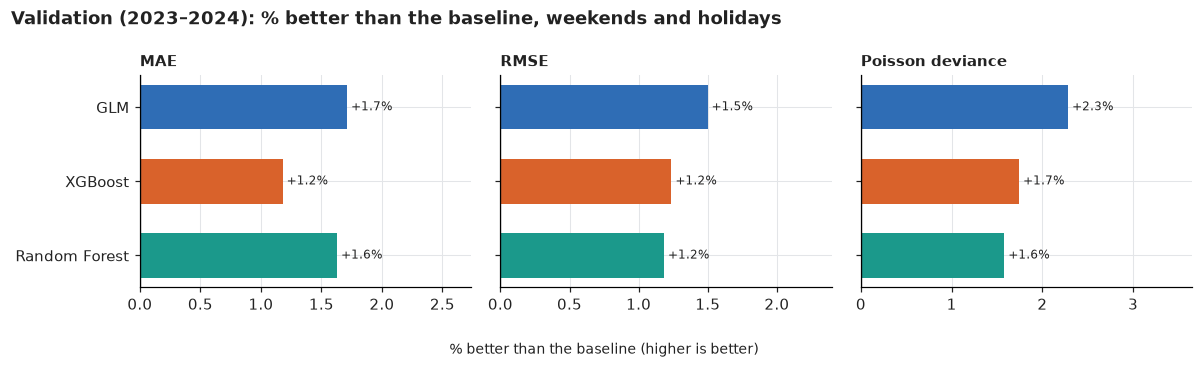

In [118]:
# 7.2. Gain over the baseline for each metric (weekends and holidays)
def plot_gains(table, names, title):
    """Horizontal bars: % better than the baseline, one panel per metric."""
    fig, axes = plt.subplots(1, 3, figsize=(11, 0.55 * len(names) + 1.6), sharey=True)
    for ax, m in zip(axes, ["MAE", "RMSE", "Poisson_dev"]):
        vals = table.loc[names, f"{m}_gain_%"]
        ax.barh([MODEL_LABELS[n] for n in names], vals, color=[MODEL_COLORS[n] for n in names], height=0.6)
        ax.axvline(0, color=DARK, lw=0.8)
        for y, v in enumerate(vals):
            ax.text(v, y, f" {v:+.1f}% ", va="center", ha="left" if v >= 0 else "right", fontsize=8, color=DARK)
        ax.set_title(m.replace("_dev", " deviance"), fontsize=10)
        lim = max(abs(vals).max() * 1.6, 1)
        ax.set_xlim(-lim if (vals < 0).any() else 0, lim)
    axes[0].invert_yaxis()
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.supxlabel("% better than the baseline (higher is better)", fontsize=9)
    plt.tight_layout(); plt.show()

plot_gains(compare_table(PREDS, COMPARE), MODELS, "Validation (2023–2024): % better than the baseline, weekends and holidays")

#### 7.3. Quarter by quarter

- **Stage:** evaluation. `plot_quarter_gains()` is reused for the final test.
- **Framework:** *Evaluation*.
- **How:** the Poisson deviance of each model in each of the 8 quarters, as % better than the baseline in that quarter. An average gain can hide quarters where a model is worse; this shows how stable the gain is.

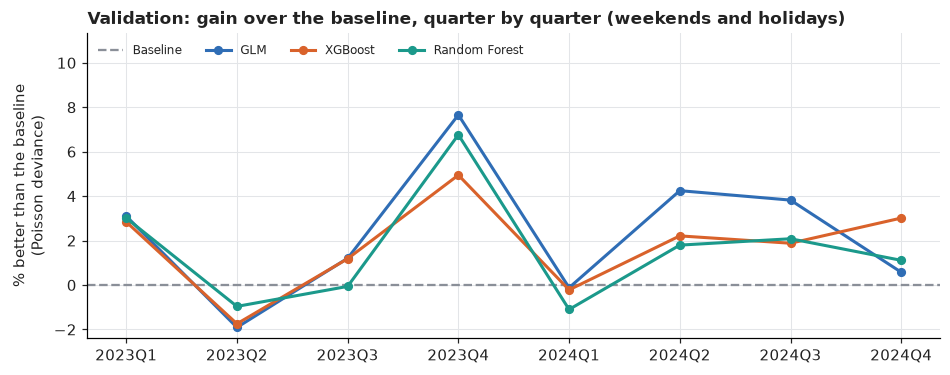

Best model per quarter: {'GLM': 5, 'Baseline': 2, 'XGBoost': 1}


,baseline_dayoff_365d,glm_poisson,xgboost,random_forest
quarter,,,,
2023Q1,1.132,1.097,1.100,1.098
2023Q2,1.235,1.259,1.257,1.247
2023Q3,1.160,1.146,1.146,1.161
2023Q4,1.167,1.078,1.109,1.088
2024Q1,1.092,1.094,1.095,1.105
2024Q2,1.186,1.136,1.160,1.165
2024Q3,1.139,1.095,1.117,1.115
2024Q4,1.077,1.071,1.044,1.065


In [119]:
# 7.3. Quarter by quarter: is the gain over the baseline stable?
def quarter_deviance(preds, names):
    """Poisson deviance per forecast quarter, on weekends and holidays."""
    return pd.DataFrame({n: dayoff_rows(preds, n).groupby("quarter")[["y", "pred"]]
                         .apply(lambda g: mean_poisson_deviance(g["y"], np.clip(g["pred"], 1e-6, None))) for n in names})

def plot_quarter_gains(preds, names, title):
    dev = quarter_deviance(preds, ["baseline_dayoff_365d"] + names)
    gain = 100 * (1 - dev[names].div(dev["baseline_dayoff_365d"], axis=0))
    fig, ax = plt.subplots(figsize=(10, 3.6))
    ax.axhline(0, color=GREY, lw=1.5, ls="--", label="Baseline")
    for n in names:
        ax.plot(gain.index, gain[n], color=MODEL_COLORS[n], lw=2, marker="o", ms=5, label=MODEL_LABELS[n])
    ax.set_ylim(top=gain.to_numpy().max() * 1.35 + 1)   # room for the legend above the lines
    ax.set(ylabel="% better than the baseline\n(Poisson deviance)", title=title)
    ax.legend(loc="upper left", ncol=len(names) + 1, fontsize=8)
    plt.show()
    return dev

dev_q = plot_quarter_gains(PREDS, MODELS, "Validation: gain over the baseline, quarter by quarter (weekends and holidays)")
print("Best model per quarter:", dev_q.idxmin(axis=1).map(MODEL_LABELS).value_counts().to_dict())
dev_q.round(3)

#### 7.4. Per region

- **Stage:** evaluation. `plot_region_gains()` is reused for the final test (9.7.2).
- **Framework:** *Evaluation*.
- **How:** the Poisson deviance per region, as % better than the baseline in that region.

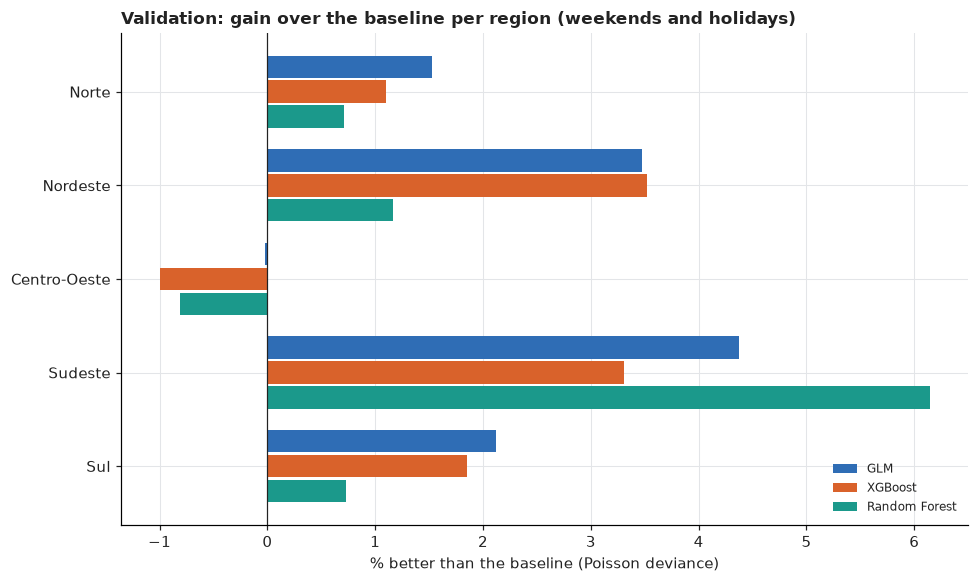

model,glm_poisson,xgboost,random_forest
region,,,
Norte,1.500,1.100,0.700
Nordeste,3.500,3.500,1.200
Centro-Oeste,-0.000,-1.000,-0.800
Sudeste,4.400,3.300,6.100
Sul,2.100,1.800,0.700


In [120]:
# 7.4. Per region: where does each model gain over the baseline?
def plot_region_gains(preds, names, title):
    """Grouped bars: % better than the baseline (Poisson deviance, weekends and holidays), per region."""
    dev = (score_table({n: preds[n] for n in ["baseline_dayoff_365d"] + names}, by="region")["Poisson_dev"]
           .unstack(0).loc[REGIONS])
    gain = 100 * (1 - dev[names].div(dev["baseline_dayoff_365d"], axis=0))
    fig, ax = plt.subplots(figsize=(9, 1.2 + 0.28 * len(REGIONS) * len(names)))
    h = 0.8 / len(names)
    for k, n in enumerate(names):
        y = np.arange(len(REGIONS)) + (k - (len(names) - 1) / 2) * h
        ax.barh(y, gain[n], height=h * 0.9, color=MODEL_COLORS[n], label=MODEL_LABELS[n])
    ax.set_yticks(np.arange(len(REGIONS)), REGIONS)
    ax.invert_yaxis()
    ax.axvline(0, color=DARK, lw=0.8)
    ax.set(xlabel="% better than the baseline (Poisson deviance)", title=title)
    ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout(); plt.show()
    return gain

plot_region_gains(PREDS, MODELS, "Validation: gain over the baseline per region (weekends and holidays)").round(1)

#### 7.5. Quarter totals

- **Stage:** evaluation. `quarter_total_errors()` and `plot_quarter_totals_all()` are reused for the final test (9.6.3).
- **Framework:** *Evaluation*.
- **How:** the total accidents with victims on weekends and holidays per quarter, actual vs each model. The table shows the average miss per region and quarter, for the 5 regions together, and the bias (`bias_%` > 0 means the model forecasts too many accidents over the 8 quarters).

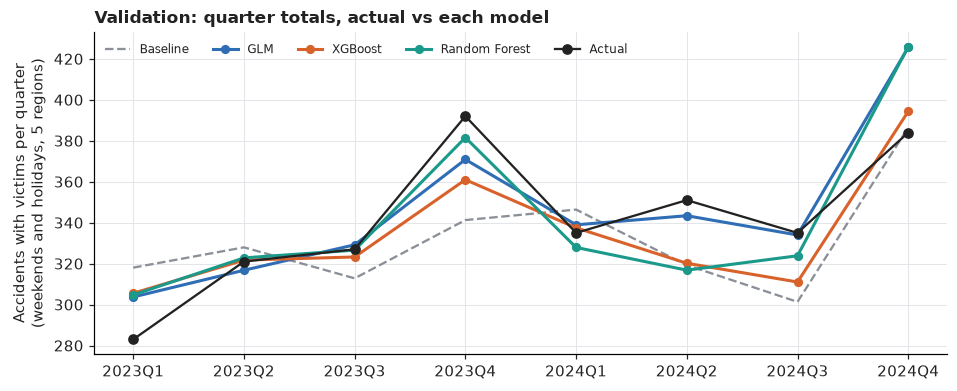

,miss_per_region_quarter_%,miss_5_regions_%,bias_%
Baseline,11.300,6.900,-2.700
GLM,10.000,3.600,1.300
XGBoost,10.400,4.600,-2.000
Random Forest,10.600,4.600,0.100


In [121]:
# 7.5. Quarter totals: what the planners see (accidents with victims per quarter, weekends and holidays, 5 regions)
def quarter_total_errors(preds, names):
    """Quarter totals on weekends and holidays: the average miss per region and quarter, for the 5 regions together, and the bias."""
    rows = {}
    for n in names:
        t = dayoff_rows(preds, n).groupby(["quarter", "region"])[["y", "pred"]].sum()
        total = t.groupby("quarter").sum()
        rows[MODEL_LABELS.get(n, n)] = {
            "miss_per_region_quarter_%": (100 * (t["pred"] / t["y"] - 1)).abs().mean(),
            "miss_5_regions_%": (100 * (total["pred"] / total["y"] - 1)).abs().mean(),
            "bias_%": 100 * (t["pred"].sum() / t["y"].sum() - 1),   # > 0 = over-forecast
        }
    return pd.DataFrame(rows).T

def plot_quarter_totals_all(preds, names, title):
    actual = dayoff_rows(preds, names[0]).groupby("quarter")["y"].sum()
    base = dayoff_rows(preds, "baseline_dayoff_365d").groupby("quarter")["pred"].sum()
    fig, ax = plt.subplots(figsize=(10, 3.8))
    ax.plot(base.index, base, color=GREY, lw=1.5, ls="--", label="Baseline")
    for n in names:
        s = dayoff_rows(preds, n).groupby("quarter")["pred"].sum()
        ax.plot(s.index, s, color=MODEL_COLORS[n], lw=2, marker="o", ms=5, label=MODEL_LABELS[n])
    ax.plot(actual.index, actual, color=DARK, lw=1.5, marker="o", ms=6, label="Actual")
    ax.set(ylabel="Accidents with victims per quarter\n(weekends and holidays, 5 regions)", title=title)
    ax.legend(loc="upper left", ncol=len(names) + 2, fontsize=8)
    plt.show()

plot_quarter_totals_all(PREDS, MODELS, "Validation: quarter totals, actual vs each model")
quarter_total_errors(PREDS, COMPARE).round(1)

#### 7.6. Result

- **Stage:** evaluation on the validation quarters (1,170 weekend/holiday rows).
- **Framework:** *Evaluation*.

| Model | MAE | RMSE | Poisson deviance | Gain over the baseline (Poisson dev.) | Best model in | Quarter-total miss, 5 regions |
|---|---|---|---|---|---|---|
| Baseline | 1.217 | 1.546 | 1.148 | — | 2 of 8 quarters | 6.9% |
| **GLM** | **1.196** | **1.523** | **1.121** | **+2.3%** | **5 of 8 quarters** | **3.6%** |
| XGBoost | 1.203 | 1.527 | 1.128 | +1.7% | 1 of 8 quarters | 4.6% |
| Random Forest | 1.197 | 1.528 | 1.130 | +1.6% | 0 of 8 quarters | 4.6% |

- **The GLM is the best model on the validation quarters**: on all three metrics, and in 5 of the 8 quarters. All three models beat the baseline, by 1.6–2.3% on the Poisson deviance.
- **The gain is not stable.** All models lose to the baseline in 2023 Q2 (by 1–2%) and slightly in 2024 Q1. The biggest gain is in 2023 Q4 (GLM about +8%), when accidents rose and the baseline, the past year's average, stayed flat. The models earn their gain when the level moves.
- **Per region:** the gains come from Sudeste (+3 to +6%) and Nordeste (+1 to +4%). In Centro-Oeste no model beats the baseline (0 to −1%).
- **Quarter totals:** the GLM misses the 5-region total by 3.6% on average, XGBoost and Random Forest by 4.6%, the baseline by 6.9%. Per region and quarter, all of them miss by about 10–11%.
- **The three models make similar errors:** same rows, same features, and mostly the same signal (the region's level). So an average of them can only help a little; section 8 tests it.

--------
## 8. Ensemble

Combine the three models into one forecast. Any weights are chosen on the validation quarters only, never on the final test.

**1. Representation:** $\hat{y} = w_1 \hat{y}_{GLM} + w_2 \hat{y}_{XGBoost} + w_3 \hat{y}_{RF}$, with weights ≥ 0 that add up to 1. With equal weights, it is the simple average.

**2. Evaluation:** the Poisson deviance on the weekend/holiday rows of the validation quarters, like every model.

**3. Optimisation:** a grid search over the weights in steps of 0.05 (231 combinations). The weights are chosen on the same quarters they are scored on, so the tuned ensemble's validation score is optimistic. It is therefore checked with **leave one quarter out**: each quarter is predicted with weights chosen on the other 7 quarters only.

- **Why an ensemble can help:** models that make different errors cancel part of each other's errors, and the forecast does not depend on one model being right.
- **Why it may not help here:** the three models use the same rows and mostly the same signal (the region's level), so their errors are similar (section 7).

| Step | What it does |
|---|---|
| 8.1 | the simple average |
| 8.2 | tuned weights, and the leave-one-quarter-out check |
| 8.3 | choose the ensemble for the final test |
| 8.4 | Result |

#### 8.1. Simple average

- **Stage:** combination + evaluation. Nothing is tuned.
- **Framework:** *Representation* (equal weights), then *Evaluation*.
- **How:** `blend()` averages the three models' validation predictions row by row. It first checks that the three models cover exactly the same rows.
- **Output:** `PREDS["ensemble_mean"]`.

In [122]:
# 8.1. Simple average of the three models: no weights to choose, so its validation score is honest
def blend(preds, weights):
    """Weighted average of the models' predictions. All models were scored on exactly the same rows."""
    names = list(weights)
    ref = preds[names[0]]
    assert all(preds[n].index.equals(ref.index) for n in names), "the models must cover the same rows"
    return ref.drop(columns="pred").assign(pred=sum(w * preds[n]["pred"].to_numpy() for n, w in weights.items()))

EQUAL_WEIGHTS = {n: 1 / len(MODELS) for n in MODELS}
PREDS["ensemble_mean"] = blend(PREDS, EQUAL_WEIGHTS)
score_table({n: PREDS[n] for n in COMPARE + ["ensemble_mean"]})

,,MAE,RMSE,Poisson_dev,n_rows
model,,,,,
baseline_dayoff_365d,all,1.217,1.546,1.148,1170
glm_poisson,all,1.196,1.523,1.121,1170
xgboost,all,1.203,1.527,1.128,1170
random_forest,all,1.197,1.528,1.130,1170
ensemble_mean,all,1.197,1.523,1.123,1170


#### 8.2. Tuned weights, checked honestly

- **Stage:** tuning.
- **Framework:** *Optimisation* at the outer level (a search over the weights), judged by the *Evaluation* metric (Poisson deviance).
- **How:**
  - Try all 231 weight combinations and keep the one with the lowest Poisson deviance on the 8 validation quarters: `ensemble_weighted`. This score is optimistic.
  - **Honest check**, `ensemble_weighted_cv`: for each quarter, choose the weights on the other 7 quarters and predict that quarter with them. The weights never see the quarter they are scored on.
- **Output:** `TUNED_WEIGHTS`, `PREDS["ensemble_weighted"]` and `PREDS["ensemble_weighted_cv"]`.

In [123]:
# 8.2. Weights chosen on the validation quarters, and an honest check of that choice (leave one quarter out)
P = np.column_stack([PREDS[n]["pred"].to_numpy() for n in MODELS])
ref = PREDS[MODELS[0]]
y, off, qtr = ref["y"].to_numpy(), ref["is_day_off"].to_numpy(), ref["quarter"].to_numpy()
WEIGHT_GRID = np.array([(i, j, 20 - i - j) for i in range(21) for j in range(21 - i)]) / 20   # steps of 0.05, sum = 1

def best_weights(mask):
    """The weights with the lowest Poisson deviance on the rows in mask."""
    devs = [mean_poisson_deviance(y[mask], np.clip(P[mask] @ w, 1e-6, None)) for w in WEIGHT_GRID]
    return WEIGHT_GRID[int(np.argmin(devs))]

# Weights chosen on all 8 validation quarters (weekends and holidays): these would go to the final test
TUNED_WEIGHTS = dict(zip(MODELS, best_weights(off)))
PREDS["ensemble_weighted"] = blend(PREDS, TUNED_WEIGHTS)

# Honest check: each quarter is predicted with weights chosen on the other 7 quarters only
cv_pred = np.empty(len(y))
for q in np.unique(qtr):
    cv_pred[qtr == q] = P[qtr == q] @ best_weights(off & (qtr != q))
PREDS["ensemble_weighted_cv"] = ref.drop(columns="pred").assign(pred=cv_pred)

print("Weights chosen on the 8 validation quarters:", {MODEL_LABELS[n]: round(w, 2) for n, w in TUNED_WEIGHTS.items()})
score_table({n: PREDS[n] for n in ["glm_poisson", "ensemble_mean", "ensemble_weighted", "ensemble_weighted_cv"]})

Weights chosen on the 8 validation quarters: {'GLM': np.float64(0.75), 'XGBoost': np.float64(0.2), 'Random Forest': np.float64(0.05)}


,,MAE,RMSE,Poisson_dev,n_rows
model,,,,,
glm_poisson,all,1.196,1.523,1.121,1170
ensemble_mean,all,1.197,1.523,1.123,1170
ensemble_weighted,all,1.196,1.522,1.121,1170
ensemble_weighted_cv,all,1.199,1.525,1.123,1170


#### 8.3. Choose the ensemble for the final test

- **Stage:** decision.
- **Framework:** *Evaluation*.
- **Rule, fixed before looking at the result:** use the tuned weights only if their leave-one-quarter-out version beats the simple average. Otherwise use the simple average, which has nothing tuned.
- **Output:** `ENSEMBLE_WEIGHTS` and `PREDS["ensemble"]`, used for the final test in section 9. The chart compares the ensemble with the three models, as in 7.2.

Ensemble used from here on: simple average {'GLM': 0.33, 'XGBoost': 0.33, 'Random Forest': 0.33}


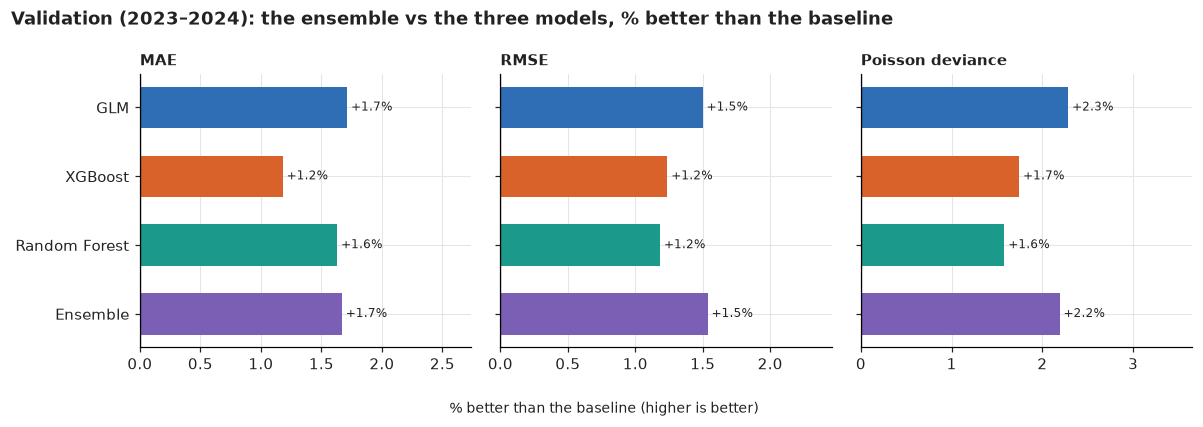

,MAE,RMSE,Poisson_dev,n_rows,MAE_gain_%,RMSE_gain_%,Poisson_dev_gain_%
model,,,,,,,
baseline_dayoff_365d,1.217,1.546,1.148,1170,0.000,0.000,0.000
glm_poisson,1.196,1.523,1.121,1170,1.712,1.499,2.284
xgboost,1.203,1.527,1.128,1170,1.180,1.237,1.744
random_forest,1.197,1.528,1.130,1170,1.630,1.183,1.581
ensemble,1.197,1.523,1.123,1170,1.669,1.536,2.189


In [124]:
# 8.3. Choose the ensemble for the final test: tuned weights only if they also win when the weights never saw the quarter
cv_dev = score_table({n: PREDS[n] for n in ["ensemble_mean", "ensemble_weighted_cv"]})["Poisson_dev"].droplevel(1)
ENSEMBLE_WEIGHTS = TUNED_WEIGHTS if cv_dev["ensemble_weighted_cv"] < cv_dev["ensemble_mean"] else EQUAL_WEIGHTS
PREDS["ensemble"] = blend(PREDS, ENSEMBLE_WEIGHTS)
print("Ensemble used from here on:", "tuned weights" if ENSEMBLE_WEIGHTS is TUNED_WEIGHTS else "simple average",
      {MODEL_LABELS[n]: round(w, 2) for n, w in ENSEMBLE_WEIGHTS.items()})

plot_gains(compare_table(PREDS, COMPARE + ["ensemble"]), MODELS + ["ensemble"],
           "Validation (2023–2024): the ensemble vs the three models, % better than the baseline")
compare_table(PREDS, COMPARE + ["ensemble"]).round(3)

#### 8.4. Result

- **Stage:** evaluation on the validation quarters (1,170 weekend/holiday rows).
- **Framework:** *Evaluation*.

| Version | MAE | RMSE | Poisson deviance |
|---|---|---|---|
| GLM alone | 1.196 | 1.523 | 1.121 |
| Simple average (GLM, XGBoost, RF: 1/3 each) | 1.197 | 1.523 | 1.123 |
| Tuned weights (GLM 0.75, XGBoost 0.20, RF 0.05), optimistic | 1.196 | 1.522 | 1.121 |
| Tuned weights, leave one quarter out (honest) | 1.199 | 1.525 | 1.123 |

- **The tuned weights put 75% on the GLM**: the best ensemble is mostly the GLM, and even then it only ties the GLM alone.
- **Leave one quarter out, the tuned weights are no better than the simple average** (1.123 both). The gain from tuning is not real, so the **simple average** goes to the final test: equal weights, nothing tuned.
- **The ensemble beats the baseline by 2.2%** (Poisson deviance): about as much as the GLM (2.3%), more than XGBoost (1.7%) and Random Forest (1.6%) alone.
- **Its value is safety:** it does not depend on one model being right. That matters if one model breaks on new data, which is what the final test checks (section 9).

--------
## 9. Final test and interpretation

Run the chosen models once on the final test quarters (2025). Which features matter, and where does the model fail?

- **Rule:** nothing is tuned or chosen on 2025. Each 2025 quarter is predicted by models trained only on the days before its cutoff, with the formula, settings and ensemble weights fixed on the validation quarters.
- **Framework:** *Evaluation* (the honest score), then interpretation.

| Step | Model | What |
|---|---|---|
| 9.1 | shared | the baselines on the 4 test quarters |
| 9.2–9.3 | Random Forest | test predictions and result |
| 9.4 | GLM and XGBoost | test predictions, with the formula and settings from sections 4 and 5 |
| 9.5 | Ensemble | the simple average from section 8 |
| 9.6 | all models | scores, validation vs test, quarter totals |
| 9.7 | all models | where the models fail: by day type and by region |
| 9.8 | all models | which features matter, and has the calendar effect changed? |
| 9.9 | all models | Result |
| 9.10 | Ensemble | forecast maps per region, for the presentation |

#### 9.1. Final test predictions (shared)

- **Stage:** final test, **used once**. Each 2025 quarter is predicted by a model trained only on the days before its cutoff, with the settings chosen on the validation quarters (sections 3–6). Nothing is tuned here.
- **Output:** `TEST_PREDS`, one entry per model, the same structure as `PREDS`, so section 7/8 code can be reused on it. Each model's owner adds its entry below.
- The two baselines are added first, as the reference. `baseline_dayoff_365d` is built for weekend/holiday days; on **all days** and on **quarter totals** it over-predicts weekdays, so `naive_all_days_365d` is the fairer reference there.

In [125]:
# 9.1. Final test predictions: one entry per model, filled model by model (role="test" = the 4 quarters of 2025)
TEST_PREDS = {}
for name in ["baseline_dayoff_365d", "naive_all_days_365d"]:
    TEST_PREDS[name] = backtest(lambda X_tr, y_tr, X_te, col=BASELINES[name]: X_te[col], [BASELINES[name]], role="test")

#### 9.2. Random Forest on the final test

- **Stage:** final test. The settings (`best_rf`, 500 trees) and the target (`RF_TARGET`) were fixed in section 6 on the validation quarters.
- **How:** the same `backtest()`, with `role="test"`: 4 forests, one per 2025 quarter, each trained on the days before that quarter's cutoff.
- **Scores:** weekends and holidays (main), all days, per region, and the total per region and quarter (the level at which resources are planned).

In [126]:
# 9.2. Random Forest on the 4 test quarters of 2025, with the settings fixed in section 6
RF_FITS = []
TEST_PREDS["random_forest"] = backtest(make_rf(*best_rf, n_estimators=500, target=RF_TARGET), FEATURES, role="test")
rf_test = {k: TEST_PREDS[k] for k in ["baseline_dayoff_365d", "naive_all_days_365d", "random_forest"]}

display(score_table(rf_test))                       # weekends and holidays (main score)
display(score_table(rf_test, day_off_only=False))   # all days
score_table(rf_test, by="region")

,,MAE,RMSE,Poisson_dev,n_rows
model,,,,,
baseline_dayoff_365d,all,1.226,1.610,1.161,585
naive_all_days_365d,all,1.223,1.606,1.156,585
random_forest,all,1.248,1.620,1.159,585


,,MAE,RMSE,Poisson_dev,n_rows
model,,,,,
baseline_dayoff_365d,all,1.201,1.566,1.130,1825
naive_all_days_365d,all,1.201,1.561,1.125,1825
random_forest,all,1.192,1.558,1.120,1825


MAE  RMSE  Poisson_dev  n_rows
model                region                                       
baseline_dayoff_365d Centro-Oeste 0.909 1.123        1.098     117
                     Nordeste     1.428 1.700        1.324     117
                     Norte        0.688 0.843        1.071     117
                     Sudeste      1.537 2.073        1.142     117
                     Sul          1.569 1.951        1.171     117
naive_all_days_365d  Centro-Oeste 0.888 1.105        1.068     117
                     Nordeste     1.416 1.679        1.300     117
                     Norte        0.695 0.849        1.090     117
                     Sudeste      1.548 2.083        1.153     117
                     Sul          1.570 1.948        1.167     117
random_forest        Centro-Oeste 0.919 1.114        1.080     117
                     Nordeste     1.481 1.742        1.373     117
                     Norte        0.656 0.815        1.004     117
                     Sudeste      1.579 2.059        1.129     117
                     Sul          1.607 1.987        1.209     117

In [127]:
# 9.2. Bias, quarter totals per region, and the Poisson noise floor on the test
from scipy.stats import poisson

def poisson_floor_mae(rate):
    """Expected MAE if a model knew the true daily rate exactly (only Poisson noise left)."""
    k = np.arange(0, 40)[:, None]
    return (poisson.pmf(k, rate[None, :]) * np.abs(k - rate[None, :])).sum(axis=0).mean()

rows = []
for name, df in rf_test.items():
    totals = df.groupby(["quarter", "region"])[["y", "pred"]].sum()
    off = df[df["is_day_off"]]
    rows.append({"model": name,
                 "bias_weekend_holiday": (off["pred"] - off["y"]).mean(),   # > 0 = over-forecast
                 "quarter_total_abs_error_%": ((totals["pred"] / totals["y"] - 1).abs().mean() * 100)})
display(pd.DataFrame(rows).set_index("model").round(3))

# Weekend/holiday uplift: accidents per day off vs per other day, actual vs forecast
rf_df = TEST_PREDS["random_forest"]
uplift = rf_df.groupby("is_day_off")[["y", "pred"]].mean()
print("Weekend/holiday uplift in 2025: actual %+.1f%%, Random Forest forecast %+.1f%%"
      % tuple((uplift.loc[True] / uplift.loc[False] - 1) * 100))

rf_off = rf_df.query("is_day_off")
print("Noise floor (weekends and holidays, 2025): MAE ~ %.3f if the daily rate were known exactly"
      % poisson_floor_mae(np.clip(rf_off["pred"].to_numpy(), 1e-3, None)))

,bias_weekend_holiday,quarter_total_abs_error_%
model,,
baseline_dayoff_365d,-0.037,10.017
naive_all_days_365d,-0.109,8.638
random_forest,0.101,7.838


Weekend/holiday uplift in 2025: actual +5.8%, Random Forest forecast +13.5%
Noise floor (weekends and holidays, 2025): MAE ~ 1.227 if the daily rate were known exactly


#### 9.3. Random Forest: result on the final test

- **Stage:** evaluation on the 4 test quarters of 2025 (585 weekend/holiday rows, 1,825 rows in total).

| Days scored | Metric | `baseline_dayoff_365d` | `naive_all_days_365d` | `random_forest` |
|---|---|---|---|---|
| Weekends and holidays | MAE / RMSE / Poisson dev. | 1.226 / 1.610 / 1.161 | **1.223 / 1.606 / 1.156** | 1.248 / 1.620 / 1.159 |
| All days | MAE / RMSE / Poisson dev. | 1.201 / 1.566 / 1.130 | 1.201 / 1.561 / 1.125 | **1.192 / 1.558 / 1.120** |
| Quarter total per region | Mean absolute error | 10.0% | 8.6% | **7.8%** |
| Weekends and holidays | Bias (forecast − actual) | −0.04 | −0.11 | +0.10 |

- **On weekends and holidays the Random Forest does not beat the baselines** (MAE 1.248 vs 1.223–1.226). Its validation gain did not carry over to 2025.
- **On all days and on quarter totals it is the best of the three**: lowest MAE, RMSE and Poisson deviance on all days, and 7.8% error on the quarterly total per region, against 8.6% and 10.0%.
- **Why weekends/holidays went wrong:** the forest over-forecast them (bias +0.10 accidents per day). In 2025 weekends and holidays had only +5.8% more accidents than other days, while the forest, trained on earlier years, forecast +13.5%. This is drift in the calendar effect, and a reason to retrain every quarter.
- **Per region:** best in Norte (MAE 0.656 vs 0.688–0.695), worse in Nordeste and Sul.
- **Noise floor:** with the rates of 2025, even a perfect daily forecast would have an MAE of about 1.23 on weekends and holidays. All three rules are within ~2% of it, so the daily differences are small next to the chance in the counts.

#### 9.4. GLM and XGBoost on the final test

- **Stage:** final test, **used once**. The GLM formula (section 4) and the XGBoost settings (`best`, section 5) were fixed on the validation quarters.
- **Framework:** *Optimisation* (each model is fitted again on the days before each 2025 cutoff, as in real use), then *Evaluation*.
- **How:** the same `backtest()` with `role="test"`: 4 models each, one per 2025 quarter. The fitted models are kept in `TEST_FITS` for 9.8.
- **Run 9.2 first:** it fits the 4 test forests (`RF_FITS`) that `TEST_FITS` also keeps.

In [128]:
# 9.4. GLM and XGBoost on the 4 test quarters of 2025, with the formula and settings fixed in sections 4 and 5
GLM_FITS = []
TEST_PREDS["glm_poisson"] = backtest(fit_predict_glm, GLM_COLS, role="test")
XGB_FITS = []
TEST_PREDS["xgboost"] = backtest(make_xgb(*best), FEATURES, role="test")
assert len(RF_FITS) == 4, "run 9.2 first: RF_FITS must hold the 4 test forests"
TEST_FITS = {"glm_poisson": GLM_FITS, "xgboost": XGB_FITS, "random_forest": RF_FITS}
score_table({n: TEST_PREDS[n] for n in ["baseline_dayoff_365d", "naive_all_days_365d", "glm_poisson", "xgboost"]})

,,MAE,RMSE,Poisson_dev,n_rows
model,,,,,
baseline_dayoff_365d,all,1.226,1.610,1.161,585
naive_all_days_365d,all,1.223,1.606,1.156,585
glm_poisson,all,1.252,1.635,1.178,585
xgboost,all,1.234,1.617,1.159,585


#### 9.5. The ensemble on the final test

- **Stage:** final test. The simple average chosen in section 8 (`ENSEMBLE_WEIGHTS`) is applied to the three models' 2025 predictions. Nothing is chosen on 2025.
- **Framework:** *Evaluation*.

In [129]:
# 9.5. The ensemble on the final test, with the weights fixed in section 8 (nothing is chosen on 2025)
TEST_PREDS["ensemble"] = blend(TEST_PREDS, ENSEMBLE_WEIGHTS)
score_table({n: TEST_PREDS[n] for n in ["baseline_dayoff_365d"] + MODELS + ["ensemble"]})

,,MAE,RMSE,Poisson_dev,n_rows
model,,,,,
baseline_dayoff_365d,all,1.226,1.610,1.161,585
glm_poisson,all,1.252,1.635,1.178,585
xgboost,all,1.234,1.617,1.159,585
random_forest,all,1.248,1.620,1.159,585
ensemble,all,1.240,1.619,1.159,585


#### 9.6. All models on the final test

- **Stage:** evaluation on 2025 (585 weekend/holiday rows, 1,825 rows on all days).
- **Framework:** *Evaluation*.
- **9.6.1:** scores and gain over the baseline, on weekends and holidays and on all days, with the same chart as 7.2. The naive all-days rule is included, because Daniel's 9.3 found it the strongest reference on 2025.
- **9.6.2:** did the validation gain hold? For each model, the gain on the validation quarters (open circle) and on the final test (filled circle).
- **9.6.3:** quarter totals, actual vs each model, and the quarter misses (as in 7.5).

,MAE,RMSE,Poisson_dev,n_rows,MAE_gain_%,RMSE_gain_%,Poisson_dev_gain_%
model,,,,,,,
baseline_dayoff_365d,1.226,1.610,1.161,585,0.000,0.000,0.000
naive_all_days_365d,1.223,1.606,1.156,585,0.230,0.277,0.485
glm_poisson,1.252,1.635,1.178,585,-2.081,-1.537,-1.409
xgboost,1.234,1.617,1.159,585,-0.665,-0.427,0.190
random_forest,1.248,1.620,1.159,585,-1.804,-0.629,0.193
ensemble,1.240,1.619,1.159,585,-1.135,-0.512,0.165


,MAE,RMSE,Poisson_dev,n_rows,MAE_gain_%,RMSE_gain_%,Poisson_dev_gain_%
model,,,,,,,
baseline_dayoff_365d,1.201,1.566,1.130,1825,0.000,0.000,0.000
naive_all_days_365d,1.201,1.561,1.125,1825,-0.026,0.279,0.470
glm_poisson,1.193,1.563,1.126,1825,0.650,0.142,0.395
xgboost,1.184,1.566,1.127,1825,1.402,-0.032,0.346
random_forest,1.192,1.558,1.120,1825,0.753,0.485,0.930
ensemble,1.187,1.558,1.119,1825,1.187,0.474,0.987


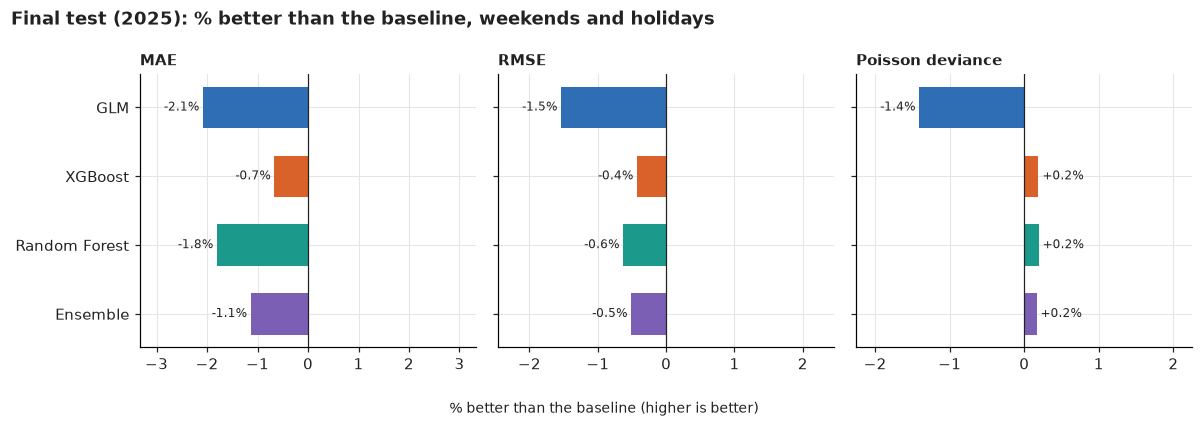

In [130]:
# 9.6.1. All models on the final test: scores and gain over the baseline (weekends and holidays, then all days)
ALL = MODELS + ["ensemble"]
TEST_COMPARE = ["baseline_dayoff_365d", "naive_all_days_365d"] + ALL
test_table = compare_table(TEST_PREDS, TEST_COMPARE)
display(test_table.round(3))
display(compare_table(TEST_PREDS, TEST_COMPARE, day_off_only=False).round(3))
plot_gains(test_table, ALL, "Final test (2025): % better than the baseline, weekends and holidays")

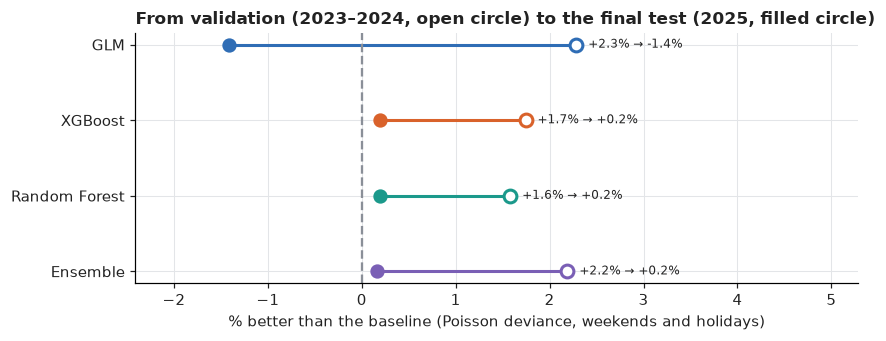

In [131]:
# 9.6.2. Did the validation gain hold on the final test? Poisson deviance gain over the baseline, validation vs test
val_gain = compare_table(PREDS, COMPARE + ["ensemble"])["Poisson_dev_gain_%"]
test_gain = test_table["Poisson_dev_gain_%"]

fig, ax = plt.subplots(figsize=(8, 3.2))
for k, n in enumerate(ALL):
    ax.plot([val_gain[n], test_gain[n]], [k, k], color=MODEL_COLORS[n], lw=2)
    ax.scatter(val_gain[n], k, s=70, facecolor="white", edgecolor=MODEL_COLORS[n], lw=2, zorder=3)
    ax.scatter(test_gain[n], k, s=70, color=MODEL_COLORS[n], zorder=3)
    ax.text(max(val_gain[n], test_gain[n]), k, f"   {val_gain[n]:+.1f}% → {test_gain[n]:+.1f}%", va="center", fontsize=8)
ax.axvline(0, color=GREY, lw=1.5, ls="--")
ax.set_yticks(range(len(ALL)), [MODEL_LABELS[n] for n in ALL])
ax.invert_yaxis()
ax.set_xlim(min(test_gain[ALL].min(), 0) - 1, max(val_gain[ALL].max(), 0) + 3)
ax.set(xlabel="% better than the baseline (Poisson deviance, weekends and holidays)",
       title="From validation (2023–2024, open circle) to the final test (2025, filled circle)")
plt.tight_layout(); plt.show()

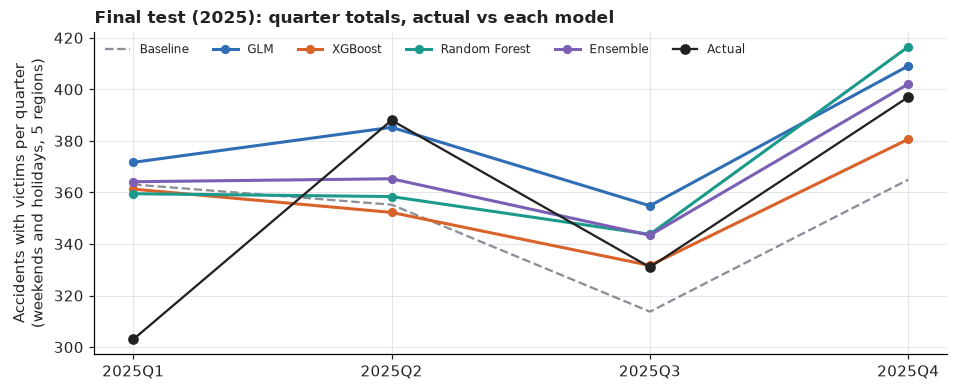

,miss_per_region_quarter_%,miss_5_regions_%,bias_%
Baseline,19.700,10.400,-1.500
Naive all days,19.000,10.900,-4.500
GLM,20.200,8.400,7.200
XGBoost,18.900,8.200,0.500
Random Forest,18.200,8.800,4.200
Ensemble,18.600,7.800,3.900


In [132]:
# 9.6.3. Quarter totals on the final test: actual vs each model, and the quarter misses
plot_quarter_totals_all(TEST_PREDS, ALL, "Final test (2025): quarter totals, actual vs each model")
quarter_total_errors(TEST_PREDS, TEST_COMPARE).round(1)

#### 9.7. Where do the models fail?

- **Stage:** evaluation (error analysis).
- **Framework:** *Evaluation*.
- **9.7.1, by day type** (weekday, weekend, holiday), on all days of 2025: the average forecast vs the actual, the bias (forecast − actual; above 0 means too high) and the MAE.
- **9.7.2, by region:** the gain over the baseline per region, as in 7.4.

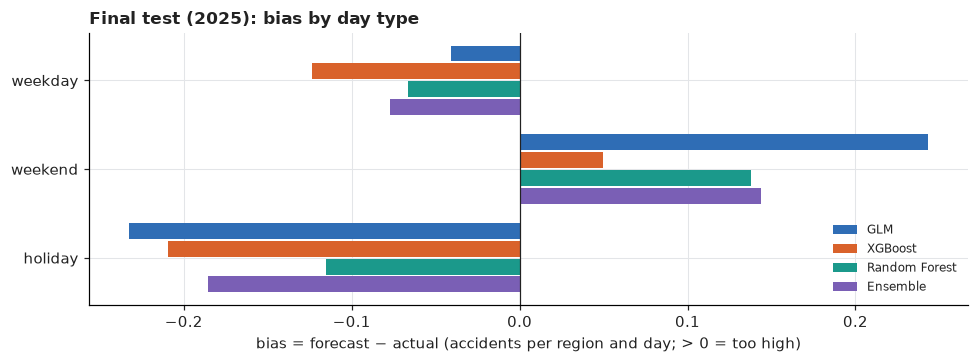

,,n_rows,actual_per_day,forecast_per_day,bias,MAE
day_type,model,,,,,
holiday,Baseline,85,2.400,2.377,-0.023,1.252
weekday,Baseline,1240,2.294,2.390,0.096,1.189
weekend,Baseline,500,2.430,2.390,-0.040,1.222
holiday,Naive all days,85,2.400,2.314,-0.086,1.231
weekday,Naive all days,1240,2.294,2.317,0.024,1.191
weekend,Naive all days,500,2.430,2.317,-0.113,1.222
holiday,GLM,85,2.400,2.167,-0.233,1.254
weekday,GLM,1240,2.294,2.253,-0.041,1.166
weekend,GLM,500,2.430,2.673,0.243,1.251


In [133]:
# 9.7.1. Errors by day type on the final test (all days): weekdays, weekends and holidays
def day_type(df):
    return np.select([df["is_holiday"] == 1, df["is_weekend"] == 1], ["holiday", "weekend"], "weekday")

rows = []
for n in ["baseline_dayoff_365d", "naive_all_days_365d"] + ALL:
    df = TEST_PREDS[n].assign(day_type=lambda d: day_type(d))
    for t, g in df.groupby("day_type"):
        rows.append({"day_type": t, "model": MODEL_LABELS[n], "n_rows": len(g), "actual_per_day": g["y"].mean(),
                     "forecast_per_day": g["pred"].mean(), "bias": (g["pred"] - g["y"]).mean(),
                     "MAE": mean_absolute_error(g["y"], g["pred"])})
by_day_type = pd.DataFrame(rows).set_index(["day_type", "model"])

# Chart: bias per day type (forecast - actual, accidents per region and day). The baseline is left out:
# it is built for weekends and holidays, so it over-forecasts weekdays by design.
bias = by_day_type["bias"].unstack("model")[[MODEL_LABELS[n] for n in ALL]].loc[["weekday", "weekend", "holiday"]]
fig, ax = plt.subplots(figsize=(9, 3.4))
h = 0.8 / len(ALL)
for k, n in enumerate(ALL):
    yy = np.arange(len(bias)) + (k - (len(ALL) - 1) / 2) * h
    ax.barh(yy, bias[MODEL_LABELS[n]], height=h * 0.9, color=MODEL_COLORS[n], label=MODEL_LABELS[n])
ax.set_yticks(range(len(bias)), bias.index)
ax.invert_yaxis()
ax.axvline(0, color=DARK, lw=0.8)
ax.set(xlabel="bias = forecast − actual (accidents per region and day; > 0 = too high)",
       title="Final test (2025): bias by day type")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()
by_day_type.round(3)

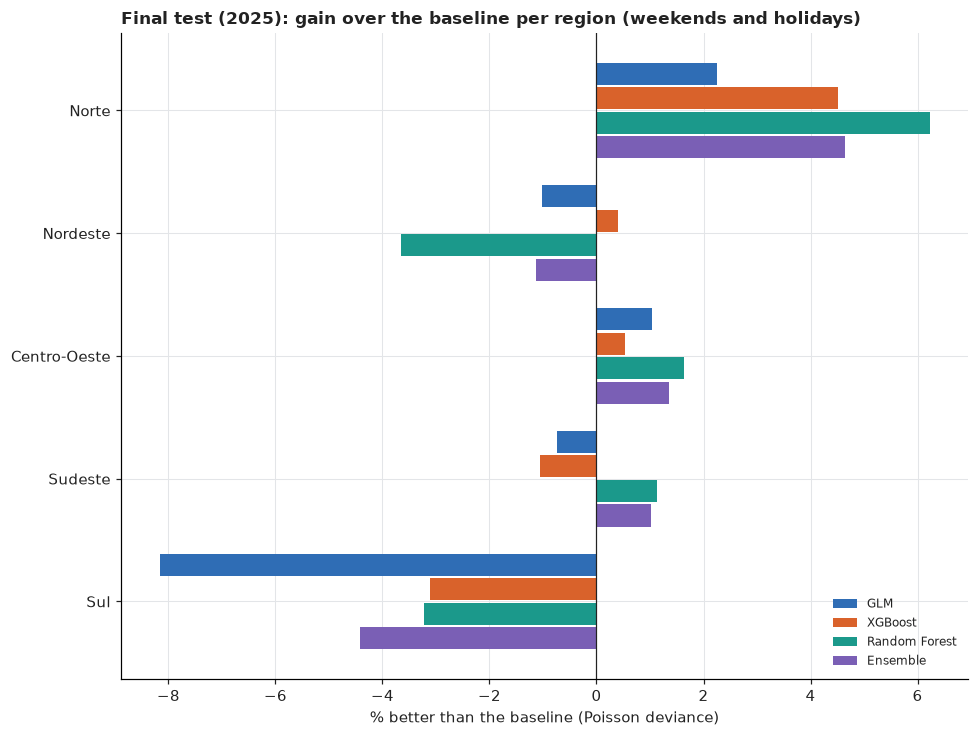

model,glm_poisson,xgboost,random_forest,ensemble
region,,,,
Norte,2.300,4.500,6.200,4.700
Nordeste,-1.000,0.400,-3.700,-1.100
Centro-Oeste,1.000,0.500,1.600,1.300
Sudeste,-0.700,-1.100,1.100,1.000
Sul,-8.200,-3.100,-3.200,-4.400


In [134]:
# 9.7.2. Errors by region on the final test: gain over the baseline (weekends and holidays)
plot_region_gains(TEST_PREDS, ALL, "Final test (2025): gain over the baseline per region (weekends and holidays)").round(1)

#### 9.8. Which features matter?

- **Stage:** interpretation.
- **Framework:** back to the *Representation*.
- **9.8.1:** permutation importance (section 2.5) of the 2025 models, each scored on the weekends and holidays of its own quarter. For the Random Forest with the ratio target, shuffling `hist_avg_365d` here also shuffles the level the prediction is multiplied by, so the level counts (unlike in 6.3).
- **9.8.2:** the GLM's calendar rate ratios, trained up to Sep 2024 and up to Sep 2025. Has the calendar effect changed?

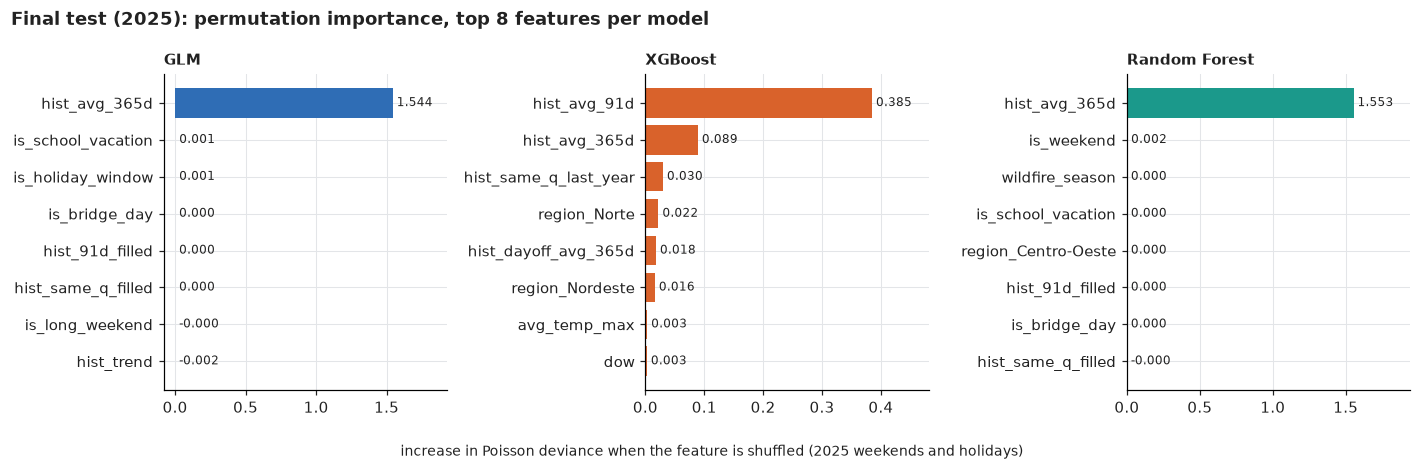

,GLM,XGBoost,Random Forest
1,hist_avg_365d (1.544),hist_avg_91d (0.385),hist_avg_365d (1.553)
2,is_school_vacation (0.001),hist_avg_365d (0.089),is_weekend (0.002)
3,is_holiday_window (0.001),hist_same_q_last_year (0.030),wildfire_season (0.000)
4,is_bridge_day (0.000),region_Norte (0.022),is_school_vacation (0.000)
5,hist_91d_filled (0.000),hist_dayoff_avg_365d (0.018),region_Centro-Oeste (0.000)
6,hist_same_q_filled (0.000),region_Nordeste (0.016),hist_91d_filled (0.000)
7,is_long_weekend (-0.000),avg_temp_max (0.003),is_bridge_day (0.000)
8,hist_trend (-0.002),dow (0.003),hist_same_q_filled (-0.000)


In [135]:
# 9.8.1. Which features matter? Permutation importance of the final-test models, each on its own 2025 quarter
rf_predict = lambda m, X: m.predict(prepare_rf(X)) * (X["hist_avg_365d"].to_numpy() if RF_TARGET == "ratio" else 1.0)
test_importance = {
    "glm_poisson": permutation_importance(TEST_FITS["glm_poisson"], glm_predict, GLM_COLS, role="test"),
    "xgboost": permutation_importance(TEST_FITS["xgboost"], xgb_predict, FEATURES, role="test"),
    "random_forest": permutation_importance(TEST_FITS["random_forest"], rf_predict, FEATURES, role="test", n_repeats=3),
}
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (n, imp) in zip(axes, test_importance.items()):
    top = imp.head(8)[::-1]
    ax.barh(top.index, top, color=MODEL_COLORS[n])
    for y, v in enumerate(top):
        ax.text(max(v, 0), y, f" {v:.3f}", va="center", fontsize=8, color=DARK)
    ax.set_xlim(right=top.max() * 1.25)
    ax.set_title(MODEL_LABELS[n], loc="left", fontsize=10)
fig.suptitle("Final test (2025): permutation importance, top 8 features per model", x=0.01, ha="left", fontweight="bold")
fig.supxlabel("increase in Poisson deviance when the feature is shuffled (2025 weekends and holidays)", fontsize=9)
plt.tight_layout(); plt.show()
pd.DataFrame({MODEL_LABELS[n]: [f"{f} ({v:.3f})" for f, v in imp.head(8).items()] for n, imp in test_importance.items()},
             index=range(1, 9))

In [136]:
# 9.8.2. Has the calendar effect changed? GLM rate ratios trained up to Sep 2024 (last validation fit) vs Sep 2025 (last test fit)
calendar_terms = [t for t in coefs.index if "day_of_week" in t] + ["C(month)[T.12]", "is_holiday", "is_long_weekend"]
drift = pd.DataFrame({
    "trained_to_sep_2024": coefs.loc[calendar_terms, "rate_ratio"],
    "trained_to_sep_2025": np.exp(TEST_FITS["glm_poisson"][-1].params[calendar_terms]),
})
drift["change_%"] = 100 * (drift["trained_to_sep_2025"] / drift["trained_to_sep_2024"] - 1)
drift.round(3)

,trained_to_sep_2024,trained_to_sep_2025,change_%
C(day_of_week)[T.Monday],0.885,0.892,0.813
C(day_of_week)[T.Saturday],1.037,1.009,-2.719
C(day_of_week)[T.Sunday],1.028,1.005,-2.310
C(day_of_week)[T.Thursday],0.762,0.779,2.184
C(day_of_week)[T.Tuesday],0.808,0.807,-0.071
C(day_of_week)[T.Wednesday],0.801,0.802,0.125
C(month)[T.12],1.128,1.147,1.730
is_holiday,0.982,0.961,-2.108
is_long_weekend,0.957,0.984,2.753


#### 9.9. Result on the final test (2025)

- **Stage:** evaluation on the 4 test quarters of 2025.
- **Framework:** *Evaluation*.

| Model | Validation gain (weekends/holidays) | **Test gain (weekends/holidays)** | Test gain (all days) | Test quarter-total miss, 5 regions | Test bias on quarter totals |
|---|---|---|---|---|---|
| Baseline | — | — | — | 10.4% | −1.5% |
| Naive all days | −1.5% | **+0.5%** | +0.5% | 10.9% | −4.5% |
| GLM | +2.3% | −1.4% | +0.4% | 8.4% | +7.2% |
| XGBoost | +1.7% | +0.2% | +0.3% | 8.2% | +0.5% |
| Random Forest | +1.6% | +0.2% | +0.9% | 8.8% | +4.2% |
| **Ensemble** | +2.2% | +0.2% | **+1.0%** | **7.8%** | +3.9% |

(Gains are % better than the baseline on the Poisson deviance.)

- **The validation gains did not hold on weekends and holidays.** In 2025 no model beats the baseline by more than 0.5%: XGBoost, Random Forest and the ensemble tie with it (+0.2%), and the GLM is 1.4% worse. The best weekend/holiday score is the naive all-days rule.
- **On all days and on quarter totals, the models still help.** The ensemble is the best on all days (+1.0%) and on the quarter totals: it misses the 5-region total by 7.8% on average, the baseline by 10.4%.
- **Why: the weekend effect shrank.** Per day, weekends had 14% more accidents than weekdays in 2023, 10% more in 2024, and only 6% more in 2025. The models learned the bigger gap from 2019–2024, so they over-forecast the 2025 weekends (the GLM by 0.24 accidents per region and day, the ensemble by 0.14). Holidays went the other way: 2.40 accidents per day in 2025 against 1.92 in 2024, and all models under-forecast them (by 0.1–0.25).
- **The GLM suffers most**, because it applies the weekend effect most strictly: Saturday and Sunday about 1.0, Monday to Thursday 0.76–0.89, relative to Friday. Training up to Sep 2025 lowers Saturday and Sunday by only 2–3% (9.8.2): the change is too recent to show in a model trained on 6 years.
- **Which features matter:** in 2025 the region's level (`hist_avg_365d`; for XGBoost `hist_avg_91d`) carries almost all of the importance. The calendar features add nothing or make the score slightly worse, while on validation the day of week was the second most important input of the GLM.
- **Where the models fail:** in Sul all models are worse than the baseline (−3 to −8%), and in Nordeste they are level with it or worse (−3.7% to +0.4%). The gain is in Norte (+2 to +6%).
- **Quarter totals:** 2025 Q1 had far fewer accidents than every forecast (303 actual, 360–372 forecast), and the range of the models did not cover it.
- **Noise floor:** with the 2025 rates, even a perfect daily forecast would have an MAE of about 1.23 on weekends and holidays (9.2). All models are within 2% of it.

#### 9.10. Forecast maps per region (for the presentation)

- **Stage:** presentation of the final forecast. No new training: it uses the ensemble's 2025 predictions from 9.5.
- **Framework:** *Evaluation* (map 3), and communicating the result.
- **Which forecast:** `MAP_MODEL = "ensemble"`, the recommended model (section 10), for `MAP_QUARTER = "2025Q4"`, the latest forecast quarter. Both can be changed: any 2025 quarter, or `"glm_poisson"`, `"xgboost"` or `"random_forest"`.
- **Three maps, one message each:**
  1. **Forecast:** how many accidents with victims to expect on weekends and holidays in each region, with the 80% range. One colour: darker = more accidents.
  2. **Change vs last year:** the forecast compared with the same quarter a year earlier, showing where to plan more (orange) or fewer (blue) resources. Grey = no change.
  3. **Forecast vs actual:** how far off the forecast was in each region. Orange = too high, blue = too low.
- **How the map is drawn:** from the state borders in `data/external/brazil_states.geojson`, grouped into the 5 macro-regions by their IBGE code. It needs only matplotlib, no extra library.
- **Files for the slides:** saved as PNG (200 dpi) in `outputs/figures/`.

In [137]:
# 9.10.1. Map of the 5 macro-regions drawn from the state borders (matplotlib only), and the numbers to show
import json
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize, TwoSlopeNorm
from matplotlib.cm import ScalarMappable
import matplotlib.patheffects as pe

MAP_MODEL, MAP_QUARTER = "ensemble", "2025Q4"   # the recommended model and the latest forecast quarter (any 2025 quarter works)
FIGURES = ROOT / "outputs/figures"               # the PNG files for the slides are saved here
FIGURES.mkdir(parents=True, exist_ok=True)

# 27 states with their IBGE code and macro-region (see data/external/README.md for the source)
GEO = json.load(open(ROOT / "data/external/brazil_states.geojson"))
STATE_SHAPES = [(f["properties"]["region"], np.array(poly[0])) for f in GEO["features"] for poly in f["geometry"]["coordinates"]]

def polygon_centre(xy):
    """Area and centre of one outline (shoelace formula)."""
    x, y = xy[:, 0], xy[:, 1]
    cross = x * np.roll(y, -1) - np.roll(x, -1) * y
    area = cross.sum() / 2
    return abs(area), ((x + np.roll(x, -1)) * cross).sum() / (6 * area), ((y + np.roll(y, -1)) * cross).sum() / (6 * area)

def region_label_points():
    """Area-weighted centre of each region, where its label goes."""
    points = {}
    for r in REGIONS:
        parts = np.array([polygon_centre(xy) for reg, xy in STATE_SHAPES if reg == r])
        points[r] = tuple(np.average(parts[:, 1:], axis=0, weights=parts[:, 0]))
    return points

LABEL_AT = region_label_points()
p_map = periods.set_index("quarter").loc[MAP_QUARTER]
MAP_NOTE = (f"Forecast made on {p_map.cutoff:%d %b %Y} by the {MODEL_LABELS[MAP_MODEL].lower()} "
            "(average of GLM, XGBoost and Random Forest). Accidents with injuries or fatalities on weekends and holidays.")

def draw_region_map(values, labels, cmap, norm, title, subtitle, cbar_label, filename, cbar_format=None):
    """Colour each region by its value, label it, add a colour bar, and save a PNG for the slides."""
    fig, ax = plt.subplots(figsize=(8.5, 8))
    ax.add_collection(PatchCollection([MplPolygon(xy, closed=True) for _, xy in STATE_SHAPES],
                                      facecolor=[cmap(norm(values[r])) for r, _ in STATE_SHAPES],
                                      edgecolor="white", linewidth=0.35))
    halo = [pe.withStroke(linewidth=3.5, foreground="white")]
    for r, (x, y) in LABEL_AT.items():
        ax.text(x, y + 0.9, r, ha="center", va="bottom", fontsize=12, fontweight="bold", color=DARK, path_effects=halo)
        ax.text(x, y + 0.6, labels[r], ha="center", va="top", fontsize=10.5, color=DARK, path_effects=halo, linespacing=1.3)
    ax.set_xlim(-74.5, -33.5)
    ax.set_ylim(-34.5, 6)
    ax.set_aspect(1.03)        # about 1 / cos(15°), so Brazil keeps its shape
    ax.axis("off")
    cbar = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.45, pad=0.0, format=cbar_format)
    cbar.set_label(cbar_label, fontsize=10)
    cbar.outline.set_visible(False)
    fig.suptitle(title, x=0.08, y=0.95, ha="left", fontsize=15, fontweight="bold")
    fig.text(0.08, 0.915, subtitle, ha="left", va="top", fontsize=10.5, color=GREY)
    fig.text(0.08, 0.06, MAP_NOTE, fontsize=8, color=GREY)
    fig.savefig(FIGURES / filename, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

# The numbers per region: forecast with its 80% range, actual, and the same quarter one year earlier
fc_map = dayoff_rows(TEST_PREDS, MAP_MODEL).query("quarter == @MAP_QUARTER").groupby("region")[["y", "pred"]].sum().loc[REGIONS]
same_q_last_year = str(pd.Period(MAP_QUARTER, freq="Q") - 4)
map_data = pd.DataFrame({
    "forecast": fc_map["pred"],
    "low_80": pd.Series(poisson.ppf(0.1, fc_map["pred"]), index=fc_map.index),
    "high_80": pd.Series(poisson.ppf(0.9, fc_map["pred"]), index=fc_map.index),
    "actual": fc_map["y"],
    "same_q_last_year": model_table[day_off & (model_table["year_quarter"] == same_q_last_year)].groupby("region")["accidents"].sum(),
}).loc[REGIONS]
map_data["change_vs_last_year_%"] = 100 * (map_data["forecast"] / map_data["same_q_last_year"] - 1)
map_data["forecast_error_%"] = 100 * (map_data["forecast"] / map_data["actual"] - 1)
map_data.round(1)

,forecast,low_80,high_80,actual,same_q_last_year,change_vs_last_year_%,forecast_error_%
region,,,,,,,
Norte,23.100,17.000,29.000,25,20,15.500,-7.600
Nordeste,91.200,79.000,104.000,72,92,-0.800,26.700
Centro-Oeste,43.500,35.000,52.000,49,40,8.700,-11.300
Sudeste,125.600,111.000,140.000,143,125,0.500,-12.200
Sul,118.700,105.000,133.000,108,107,10.900,9.900


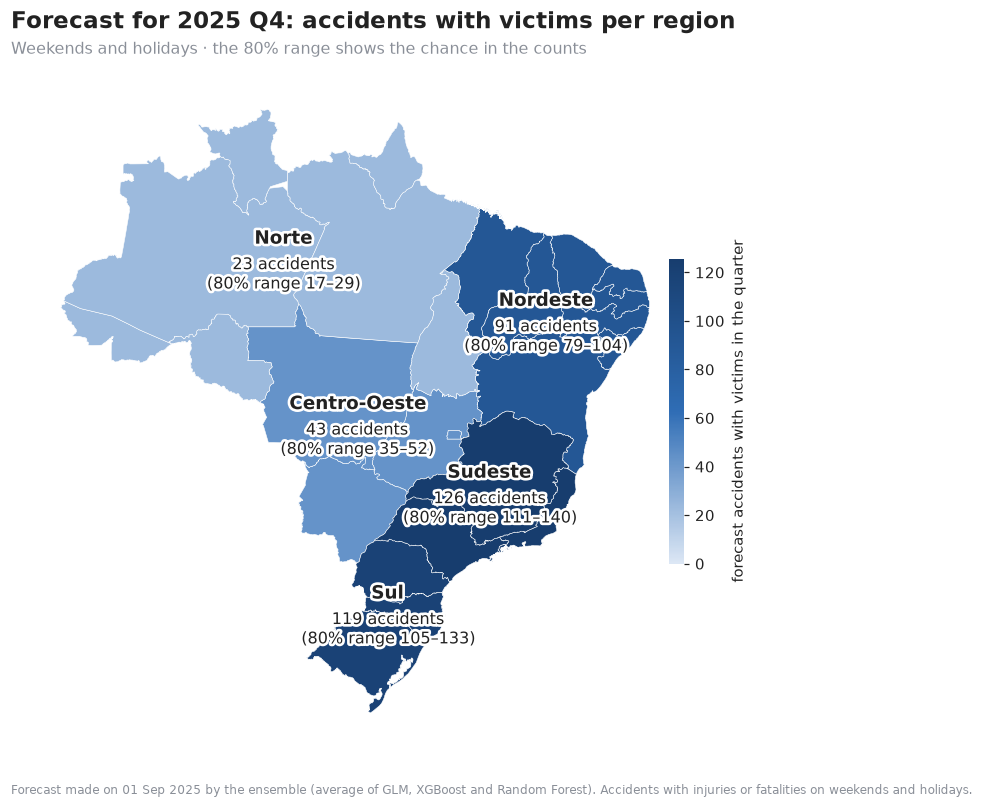

In [138]:
# 9.10.2. Map 1 - the forecast per region, with its 80% range
seq_blue = LinearSegmentedColormap.from_list("seq_blue", ["#DCE7F5", BLUE, "#173D6E"])   # one hue, light = few, dark = many
draw_region_map(
    values=map_data["forecast"],
    labels={r: f"{v.forecast:.0f} accidents\n(80% range {v.low_80:.0f}–{v.high_80:.0f})" for r, v in map_data.iterrows()},
    cmap=seq_blue, norm=Normalize(0, map_data["forecast"].max()),
    title=f"Forecast for {MAP_QUARTER[:4]} {MAP_QUARTER[4:]}: accidents with victims per region",
    subtitle="Weekends and holidays · the 80% range shows the chance in the counts",
    cbar_label="forecast accidents with victims in the quarter",
    filename=f"map1_forecast_{MAP_QUARTER}.png")

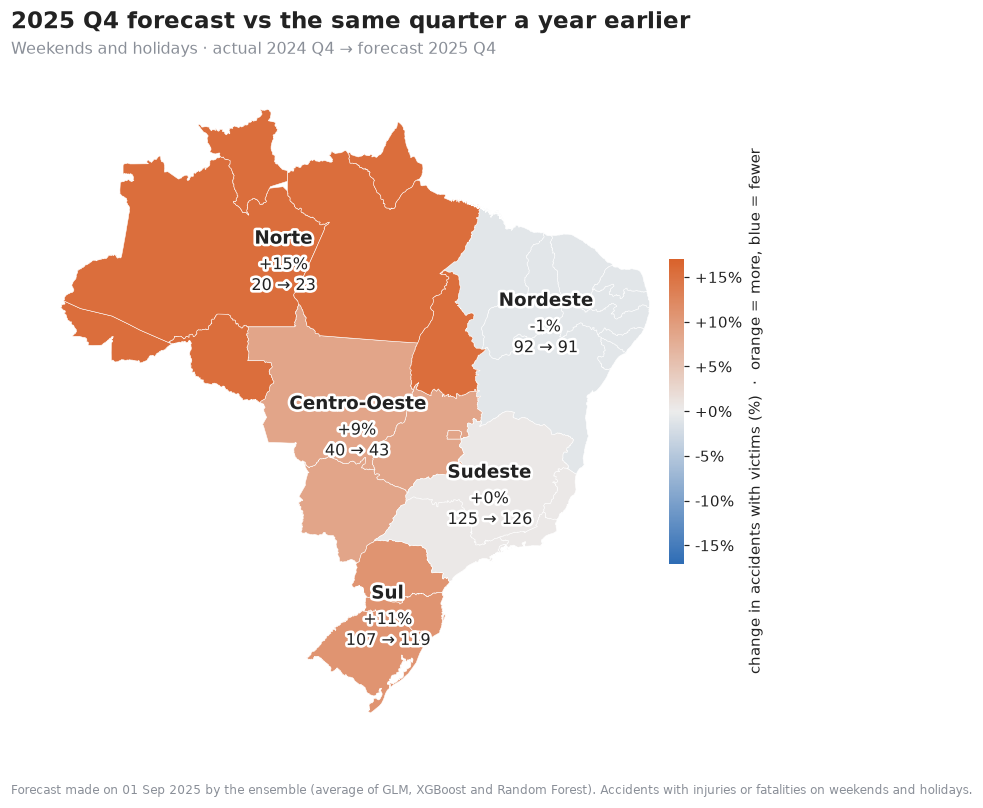

In [139]:
# 9.10.3. Map 2 - the forecast compared with the same quarter one year earlier (where to plan more or fewer resources)
diverging = LinearSegmentedColormap.from_list("diverging", [BLUE, "#ECECEC", ORANGE])   # two hues, grey = no change
lim = max(10, map_data["change_vs_last_year_%"].abs().max() * 1.1)
draw_region_map(
    values=map_data["change_vs_last_year_%"],
    labels={r: f"{v['change_vs_last_year_%']:+.0f}%\n{v.same_q_last_year:.0f} → {v.forecast:.0f}" for r, v in map_data.iterrows()},
    cmap=diverging, norm=TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim),
    title=f"{MAP_QUARTER[:4]} {MAP_QUARTER[4:]} forecast vs the same quarter a year earlier",
    subtitle=f"Weekends and holidays · actual {same_q_last_year[:4]} {same_q_last_year[4:]} → forecast {MAP_QUARTER[:4]} {MAP_QUARTER[4:]}",
    cbar_label="change in accidents with victims (%)  ·  orange = more, blue = fewer",
    filename=f"map2_change_vs_last_year_{MAP_QUARTER}.png", cbar_format="%+.0f%%")

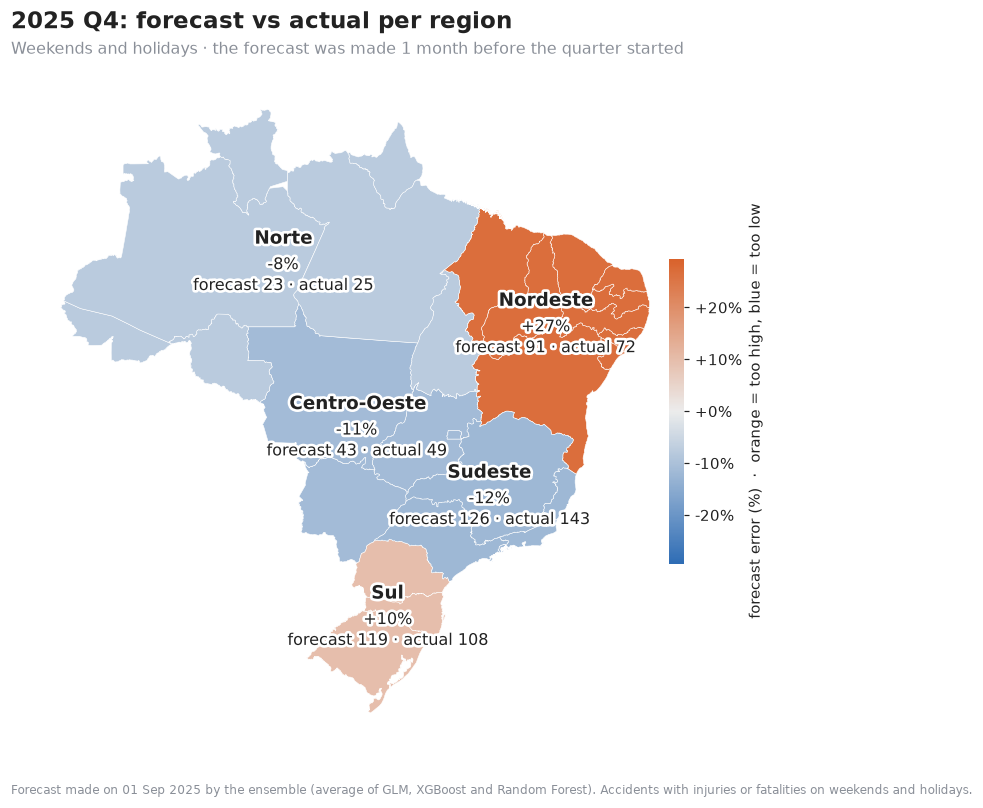

Saved for the slides: ['map1_forecast_2025Q4.png', 'map2_change_vs_last_year_2025Q4.png', 'map3_forecast_vs_actual_2025Q4.png']


In [140]:
# 9.10.4. Map 3 - how far the forecast was from what happened (forecast vs actual)
lim = max(10, map_data["forecast_error_%"].abs().max() * 1.1)
draw_region_map(
    values=map_data["forecast_error_%"],
    labels={r: f"{v['forecast_error_%']:+.0f}%\nforecast {v.forecast:.0f} · actual {v.actual:.0f}" for r, v in map_data.iterrows()},
    cmap=diverging, norm=TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim),
    title=f"{MAP_QUARTER[:4]} {MAP_QUARTER[4:]}: forecast vs actual per region",
    subtitle="Weekends and holidays · the forecast was made 1 month before the quarter started",
    cbar_label="forecast error (%)  ·  orange = too high, blue = too low",
    filename=f"map3_forecast_vs_actual_{MAP_QUARTER}.png", cbar_format="%+.0f%%")
print("Saved for the slides:", sorted(f.name for f in FIGURES.glob(f"map*_{MAP_QUARTER}.png")))

**What the maps show** (2025 Q4, ensemble, weekends and holidays)

| Region | Forecast (80% range) | Same quarter 2024 | Change | Actual | Forecast error |
|---|---|---|---|---|---|
| Norte | 23 (17–29) | 20 | +15% | 25 | −8% |
| Nordeste | 91 (79–104) | 92 | −1% | 72 | +27% |
| Centro-Oeste | 43 (35–52) | 40 | +9% | 49 | −11% |
| Sudeste | 126 (111–140) | 125 | 0% | 143 | −12% |
| Sul | 119 (105–133) | 107 | +11% | 108 | +10% |
| **5 regions** | **402** | **384** | **+5%** | **397** | **+1%** |

- **Map 1, the forecast:** Sudeste and Sul account for about 60% of the 402 accidents with victims expected on the weekends and holidays of 2025 Q4. Norte expects about 23.
- **Map 2, the change:** the ensemble expected more accidents than in 2024 Q4 in Norte (+15%), Sul (+11%) and Centro-Oeste (+9%), and about the same in Nordeste and Sudeste. For the 5 regions together that is +5%.
- **Map 3, the accuracy:** for the 5 regions together the forecast was almost exact (402 vs 397, +1%), but the regions missed in both directions, and the misses cancelled out. Nordeste was 27% too high (72 actual, below its 80% range) and Sudeste 12% too low (143, above its range). In Norte, −8% is 2 accidents.
- **For the slides:** map 1 is the forecast, map 2 is what changes, map 3 is how much to trust it. Map 3 supports the recommendation in section 10: plan per region with the 80% range, and watch the regions where the forecast missed most.

--------
## 10. Conclusions and limitations

### Conclusions

1. **A simple, well-built rule is hard to beat.** The baseline, each region's average weekend/holiday day of the past year, is within a few percent of what any model can reach. With about 2.3 accidents per region and day, most of the day-to-day variation is chance (Poisson noise): even a perfect forecast of the daily rate would have an MAE of about 1.2.
2. **On validation (2023–2024), all models beat the baseline**, by 1.6–2.3% on the Poisson deviance. The GLM was the best: a coefficient of about 1 on the region's level, plus day-of-week and December effects. The tree models found no extra signal; their best settings were the simplest ones (depth-2 trees, large leaves).
3. **On the final test (2025), the gain on weekends and holidays disappeared** (−1.4% to +0.5%). The weekend effect shrank (from +14% to +6% over weekdays) and holidays had more accidents than before, so the calendar pattern the models learned no longer fit. The models still forecast all days and the quarter totals better than the baseline (ensemble: 7.8% average miss on the 5-region quarter total, against 10.4%).
4. **The ensemble is the safest choice.** It was never the worst model; in 2025 it was the best on all days and on quarter totals; and it does not depend on one model being right. The GLM is the easiest to explain (rate ratios), but it suffered most from the change in the weekend effect.
5. **For the planners:** use the forecast as a quarter total per region with its 80% range, not as an exact daily count. The small regions (Norte, Centro-Oeste) need the range most: there, a miss of 3 accidents is already about 15% of a quarter.

### Recommendation

- Use the **ensemble** (the simple average of GLM, XGBoost and Random Forest) for the quarterly plan, with the baseline next to it as a check.
- **Retrain every quarter** at the cutoff, as the rolling backtest already does, and **monitor the weekend and holiday uplift**. If it keeps drifting away from what the models learned, give more weight to recent data: for example, train on the last 2–3 years only, or add a feature with the recent weekend uplift per region.

### Limitations

- **Little signal:** the target is a small count per region and day, so all scores are close to the Poisson noise floor. Differences of 1–2% between models could change with one more year of data.
- **The validation score is optimistic:** the GLM formula, the tree settings and the ensemble rule were chosen on the 8 validation quarters. The final test is the honest score, but it is small: 4 quarters, 585 weekend/holiday rows.
- **Drift:** the calendar pattern changed in 2025 (weekends lower, holidays higher). Models trained on 2019–2024 assume the old pattern.
- **COVID:** the COVID days (16 March – 30 June 2020) are left out of training, and some history features inside the COVID gap were filled (about 4% of the training rows).
- **Sample data:** the project uses a sample of 150,000 accident records, not the full dataset, so the counts per region and day are smaller than the real ones.
- **No information after the cutoff:** the forecast is made 1 month ahead, so it cannot use weather forecasts, traffic volumes or events. The weather columns are monthly averages only.
- **Severity:** injuries and fatalities are forecast together. Fatal accidents (about 7–13% depending on the region) need different resources; a separate model for the fatal share would help the planners.
- **The 80% range covers only Poisson chance**, not the uncertainty of the model itself, so it is too narrow when the level is wrong (2024 Q4 for the GLM; 2025 Q1 for all models).